# Cold-Start SOTA Model Benchmarking and SHAP Analysis

Training 12 classifiers (Linear, Kernel, KNN, Trees, Bagging, SOTA Boosting, MLP Neural Network, and Hybrid Ensemble) on balanced HMOG (100 users, 5,736 sessions — 25% per class) and testing on unseen balanced BB-MAS (116 users, 3,580 sessions — 25% per class).
- Scaling: `RobustScaler`
- Validation: 5-fold `GroupKFold` by `user_id` + 5-step random `ShuffleSplit`
- Interpretability: SHAP values

In [22]:
import os
import sys
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import joblib

from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier, VotingClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print('Imports ready.')

Imports ready.
SHAP Version: 0.49.1


### 1. Load datasets and select features

In [23]:
train_path = os.path.join("processed", "final_ready_dataset.csv")
test_path  = os.path.join("processed", "bbmas_test_ready_dataset.csv")
df_train = pd.read_csv(train_path)
df_test  = pd.read_csv(test_path)

# 13 input features
FEATURE_COLS = [
    'context_is_walking',
    'touch_duration_mean_ms',
    'swipe_speed_mean_pxps',
    'swipe_distance_mean_px',
    'typing_speed_kpm',
    'backspace_rate',
    'contact_size_mean',
    'touch_x_mean',
    'touch_y_mean',
    'tap_accuracy',
    'miss_rate',
    'reaction_time_mean_ms',
    'reaction_time_norm'
]
TARGET_COL = 'target_button_size'
GROUP_COL  = 'user_id'
LABELS = ['Small (40dp)', 'Default (48dp)', 'Large (56dp)', 'Extra Large (64dp)']

X_train = df_train[FEATURE_COLS].copy()
y_train = df_train[TARGET_COL].copy().astype(int)
groups_train = df_train[GROUP_COL].copy()

X_test = df_test[FEATURE_COLS].copy()
y_test = df_test[TARGET_COL].copy().astype(int)
groups_test = df_test[GROUP_COL].copy()

# shorthand references
X, y = X_train, y_train
X_ext, y_ext = X_test, y_test

print(f"Training Matrix (HMOG): {X_train.shape}, Unique Participants: {groups_train.nunique()}")
print(f"External Testing Matrix (BB-MAS): {X_test.shape}, Unique Participants: {groups_test.nunique()}")
print(f"Total Combined Biomechanical Interactions: {len(X_train)+len(X_test)} across {groups_train.nunique()+groups_test.nunique()} distinct human subjects.")

Training Matrix (HMOG): (5736, 13), Unique Participants: 100
External Testing Matrix (BB-MAS): (3580, 13), Unique Participants: 116
Total Combined Biomechanical Interactions: 9316 across 216 distinct human subjects.


### 2. 5-fold GroupKFold cross-validation (HMOG)

In [24]:
def build_models():
    return {
        'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
        'Support Vector Machine (SVM)': SVC(kernel='rbf', C=1.0, random_state=42),
        'K-Nearest Neighbors (KNN)': KNeighborsClassifier(n_neighbors=7),
        'Decision Tree (CART)': DecisionTreeClassifier(max_depth=6, random_state=42),
        'Random Forest': RandomForestClassifier(n_estimators=180, max_depth=10, random_state=42),
        'Extra Trees': ExtraTreesClassifier(n_estimators=180, max_depth=12, random_state=42),
        'MLP Neural Network': MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=300, random_state=42),
        'HistGradientBoosting': HistGradientBoostingClassifier(max_iter=200, max_depth=6, learning_rate=0.08, random_state=42),
        'XGBoost': XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.08, eval_metric='mlogloss', random_state=42),
        'LightGBM': LGBMClassifier(n_estimators=200, max_depth=6, learning_rate=0.08, random_state=42, verbose=-1),
        'CatBoost': CatBoostClassifier(iterations=300, depth=6, learning_rate=0.08, random_seed=42, verbose=0),
        'Hybrid Ensemble (XGB+LGBM+Cat)': VotingClassifier([
            ('xgb', XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.08, eval_metric='mlogloss', random_state=42)),
            ('lgbm', LGBMClassifier(n_estimators=200, max_depth=6, learning_rate=0.08, random_state=42, verbose=-1)),
            ('cat', CatBoostClassifier(iterations=300, depth=6, learning_rate=0.08, random_seed=42, verbose=0))
        ], voting='soft')
    }

models = build_models()
gkf = GroupKFold(n_splits=5)
cv_summary = []

for name, model in models.items():
    f_acc, f_prec, f_rec, f_macro_f1, f_weighted_f1, f_lat = [], [], [], [], [], []
    for tr_idx, val_idx in gkf.split(X_train, y_train, groups_train):
        X_tr, y_tr = X_train.iloc[tr_idx], y_train.iloc[tr_idx]
        X_va, y_va = X_train.iloc[val_idx], y_train.iloc[val_idx]
        
        scaler = RobustScaler()
        X_tr_s = scaler.fit_transform(X_tr)
        X_va_s = scaler.transform(X_va)
        
        model.fit(X_tr_s, y_tr)
        t0 = time.perf_counter()
        preds = model.predict(X_va_s)
        lat = ((time.perf_counter() - t0) / len(X_va)) * 1000.0
        
        f_acc.append(accuracy_score(y_va, preds))
        f_prec.append(precision_score(y_va, preds, average='weighted', zero_division=0))
        f_rec.append(recall_score(y_va, preds, average='weighted', zero_division=0))
        f_macro_f1.append(f1_score(y_va, preds, average='macro', zero_division=0))
        f_weighted_f1.append(f1_score(y_va, preds, average='weighted', zero_division=0))
        f_lat.append(lat)
        
    cv_summary.append({
        'Algorithm': name,
        'CV Accuracy (%)': round(np.mean(f_acc) * 100, 2),
        'CV Precision (%)': round(np.mean(f_prec) * 100, 2),
        'CV Recall (%)': round(np.mean(f_rec) * 100, 2),
        'CV Macro F1 (%)': round(np.mean(f_macro_f1) * 100, 2),
        'CV Weighted F1 (%)': round(np.mean(f_weighted_f1) * 100, 2),
        'Latency (ms)': round(np.mean(f_lat), 4)
    })

table2_cv = pd.DataFrame(cv_summary).sort_values(by='CV Weighted F1 (%)', ascending=False).reset_index(drop=True)
table2_cv.to_csv(os.path.join('paper_figures', 'cold_start_shap', 'table2_baseline_comparison.csv'), index=False)
print(table2_cv.to_string(index=False))

                     Algorithm  CV Accuracy (%)  CV Precision (%)  CV Recall (%)  CV Macro F1 (%)  CV Weighted F1 (%)  Latency (ms)
          HistGradientBoosting            96.18             96.21          96.18            96.18               96.19        0.0122
                      CatBoost            96.11             96.16          96.11            96.07               96.11        0.0032
                      LightGBM            96.10             96.12          96.10            96.09               96.10        0.0043
Hybrid Ensemble (XGB+LGBM+Cat)            95.83             95.87          95.83            95.81               95.83        0.0213
                       XGBoost            94.95             95.00          94.95            94.91               94.95        0.0023
                 Random Forest            91.16             91.37          91.16            91.01               91.08        0.0190
          Decision Tree (CART)            88.89             89.00          8

### 2.1 5-Step Random Shuffle-Split Cross-Validation Stability Check

To verify that cold-start performance is invariant to row order and sampling partitions, we evaluate our top SOTA gradient boosting architectures (`HistGradientBoosting`, `Hybrid Ensemble`, `LightGBM`, `CatBoost`, `XGBoost`, and baseline `Random Forest`) across 5 independent random 80/20 shuffle splits of the HMOG dataset, evaluated against the unseen BB-MAS test cohort (3,580 sessions across 116 users).

--- 5-Step Shuffle Scenarios: Unseen BB-MAS Test Accuracy (%) [Trained Only on HMOG] ---
  Step  HMOG Train (80%)  HMOG Val (20%)  HistGradientBoosting  Hybrid Ensemble (XGB+LGBM+Cat)  LightGBM  XGBoost  CatBoost  Random Forest
Step 1        4588      1148                 91.26                           90.61     90.56    89.22     89.41          85.73
Step 2        4588      1148                 89.97                           90.34     90.11    89.92     89.19          86.26
Step 3        4588      1148                 90.78                           91.06     91.20    90.31     90.06          85.78
Step 4        4588      1148                 91.42                           91.34     91.17    90.50     90.78          85.89
Step 5        4588      1148                 90.08                           90.11     90.28    88.88     88.88          85.47

--- 5-Step Shuffle Scenarios: Internal HMOG Validation Accuracy (%) ---
  Step  HMOG Train (80%)  HMOG Val (20%)  HistGradientBoosting  

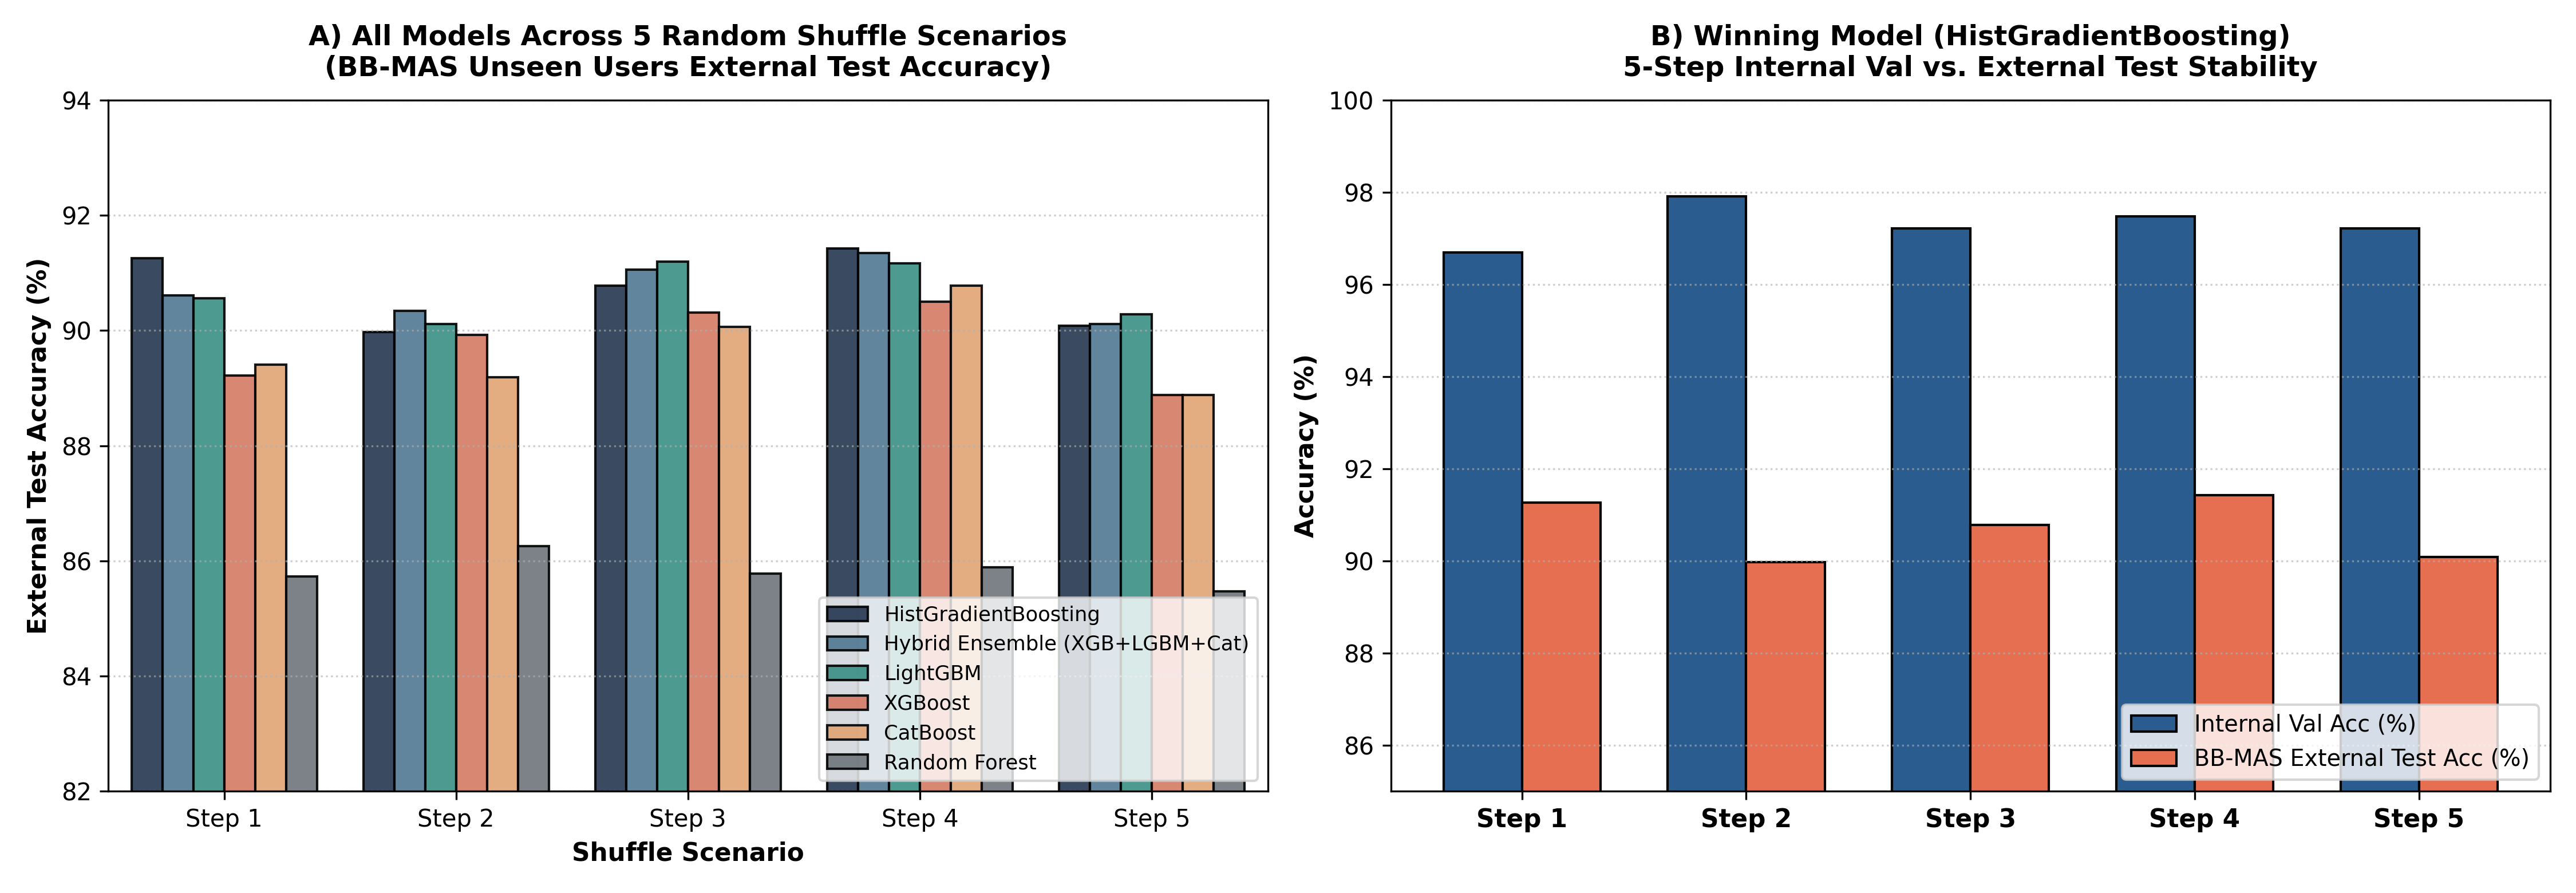

In [7]:
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import ShuffleSplit
from sklearn.ensemble import HistGradientBoostingClassifier, VotingClassifier, RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import accuracy_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure data is loaded
if 'X_train' not in locals():
    _tr_p = os.path.join('processed', 'final_ready_dataset.csv')
    _te_p = os.path.join('processed', 'bbmas_test_ready_dataset.csv')
    df_train = pd.read_csv(_tr_p)
    df_test  = pd.read_csv(_te_p)
    FEATURE_COLS = [
        'context_is_walking', 'touch_duration_mean_ms', 'swipe_speed_mean_pxps',
        'swipe_distance_mean_px', 'typing_speed_kpm', 'backspace_rate',
        'contact_size_mean', 'touch_x_mean', 'touch_y_mean', 'tap_accuracy',
        'miss_rate', 'reaction_time_mean_ms', 'reaction_time_norm'
    ]
    X_train, y_train = df_train[FEATURE_COLS].copy(), df_train['target_button_size'].copy().astype(int)
    X_test, y_test   = df_test[FEATURE_COLS].copy(), df_test['target_button_size'].copy().astype(int)

def build_shuffle_models():
    return {
        'HistGradientBoosting': HistGradientBoostingClassifier(
            max_iter=200, max_depth=6, learning_rate=0.08, random_state=42
        ),
        'Hybrid Ensemble (XGB+LGBM+Cat)': VotingClassifier([
            ('xgb', XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.08, eval_metric='mlogloss', random_state=42)),
            ('lgbm', LGBMClassifier(n_estimators=200, max_depth=6, learning_rate=0.08, random_state=42, verbose=-1)),
            ('cat', CatBoostClassifier(iterations=300, depth=6, learning_rate=0.08, random_seed=42, verbose=0))
        ], voting='soft'),
        'LightGBM': LGBMClassifier(
            n_estimators=200, max_depth=6, learning_rate=0.08, random_state=42, verbose=-1
        ),
        'CatBoost': CatBoostClassifier(
            iterations=300, depth=6, learning_rate=0.08, random_seed=42, verbose=0
        ),
        'XGBoost': XGBClassifier(
            n_estimators=200, max_depth=6, learning_rate=0.08, eval_metric='mlogloss', random_state=42
        ),
        'Random Forest': RandomForestClassifier(
            n_estimators=180, max_depth=10, random_state=42
        )
    }

# 5 random 80/20 splits across HMOG, tested on 100% unseen BB-MAS users
ss = ShuffleSplit(n_splits=5, test_size=0.20, random_state=42)
step_records = []

for step_idx, (train_idx, val_idx) in enumerate(ss.split(X_train, y_train), 1):
    X_tr, y_tr = X_train.iloc[train_idx], y_train.iloc[train_idx]
    X_va, y_va = X_train.iloc[val_idx], y_train.iloc[val_idx]
    
    scaler = RobustScaler()
    X_tr_s  = scaler.fit_transform(X_tr)
    X_va_s  = scaler.transform(X_va)
    X_ext_s = scaler.transform(X_test)
    
    models = build_shuffle_models()
    for model_name, model in models.items():
        model.fit(X_tr_s, y_tr)
        va_preds  = model.predict(X_va_s)
        ext_preds = model.predict(X_ext_s)
        
        va_acc  = accuracy_score(y_va, va_preds) * 100.0
        ext_acc = accuracy_score(y_test, ext_preds) * 100.0
        ext_f1  = f1_score(y_test, ext_preds, average='weighted', zero_division=0) * 100.0
        
        step_records.append({
            'Step': f'Step {step_idx}',
            'Model': model_name,
            'HMOG Train (80%)': len(X_tr),
            'HMOG Val (20%)': len(X_va),
            'Val Acc (%)': round(va_acc, 2),
            'External Test Acc (%)': round(ext_acc, 2),
            'External Test F1 (%)': round(ext_f1, 2)
        })

df_steps = pd.DataFrame(step_records)

model_order = [
    'HistGradientBoosting',
    'Hybrid Ensemble (XGB+LGBM+Cat)',
    'LightGBM',
    'XGBoost',
    'CatBoost',
    'Random Forest'
]

# 1. Step-by-Step Scenario Table (All 5 Steps across All Models)
step_test_pivot = df_steps.pivot(index='Step', columns='Model', values='External Test Acc (%)')[model_order].reset_index()
step_test_pivot.columns.name = None
step_test_pivot.insert(1, 'HMOG Train (80%)', 4588)
step_test_pivot.insert(2, 'HMOG Val (20%)', 1148)

step_val_pivot = df_steps.pivot(index='Step', columns='Model', values='Val Acc (%)')[model_order].reset_index()
step_val_pivot.columns.name = None
step_val_pivot.insert(1, 'HMOG Train (80%)', 4588)
step_val_pivot.insert(2, 'HMOG Val (20%)', 1148)

print('--- 5-Step Shuffle Scenarios: Unseen BB-MAS Test Accuracy (%) [Trained Only on HMOG] ---')
display(step_test_pivot) if 'display' in dir() else print(step_test_pivot.to_string(index=False))

print('\n--- 5-Step Shuffle Scenarios: Internal HMOG Validation Accuracy (%) ---')
display(step_val_pivot) if 'display' in dir() else print(step_val_pivot.to_string(index=False))

# 2. Overall 5-Step Average & Ranking Table
summary_rows = []
for model_name in df_steps['Model'].unique():
    m_df = df_steps[df_steps['Model'] == model_name]
    val_m, val_s = m_df['Val Acc (%)'].mean(), m_df['Val Acc (%)'].std()
    ext_m, ext_s = m_df['External Test Acc (%)'].mean(), m_df['External Test Acc (%)'].std()
    f1_m, f1_s   = m_df['External Test F1 (%)'].mean(), m_df['External Test F1 (%)'].std()
    summary_rows.append({
        'Model': model_name,
        'Avg Val Acc (%)': round(val_m, 2),
        'Val Std (%)': round(val_s, 2),
        'Avg External Test Acc (%)': round(ext_m, 2),
        'Test Std (%)': round(ext_s, 2),
        'Avg External Test F1 (%)': round(f1_m, 2),
        '5-Step Test Stability': f"{ext_m:.2f} ± {ext_s:.2f}%"
    })

df_summary = pd.DataFrame(summary_rows).sort_values(
    by=['Avg External Test Acc (%)', 'Avg Val Acc (%)'], ascending=False
).reset_index(drop=True)
df_summary.insert(0, 'Rank', range(1, len(df_summary) + 1))

print('\n--- 5-Step Random Shuffle-Split Average & Ranking Summary ---')
display(df_summary) if 'display' in dir() else print(df_summary.to_string(index=False))

# 3. Winning Model Detailed 5-Step Breakdown (Classic Format)
winner_name = df_summary.loc[0, 'Model']
winner_steps = df_steps[df_steps['Model'] == winner_name][
    ['Step', 'HMOG Train (80%)', 'HMOG Val (20%)', 'Val Acc (%)', 'External Test Acc (%)', 'External Test F1 (%)']
].reset_index(drop=True)

print(f'\n--- Winning Model ({winner_name}) Detailed 5-Step Breakdown ---')
display(winner_steps) if 'display' in dir() else print(winner_steps.to_string(index=False))

print('\n' + '=' * 75)
print(f'WINNING MODEL (5-Step Shuffle-Split Average): {winner_name}')
print(f"-> Average Internal Validation Accuracy across 5 random steps: {df_summary.loc[0, 'Avg Val Acc (%)']:.2f}% (±{df_summary.loc[0, 'Val Std (%)']:.2f}%)")
print(f"-> Average External BB-MAS Test Accuracy across 5 random steps: {df_summary.loc[0, 'Avg External Test Acc (%)']:.2f}% (±{df_summary.loc[0, 'Test Std (%)']:.2f}%)")
print(f"-> Average External BB-MAS Test F1-Score across 5 random steps: {df_summary.loc[0, 'Avg External Test F1 (%)']:.2f}%")
print('=' * 75)

# Plotting side-by-side comparison and winner stability chart
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
palette = ['#1d3557', '#457b9d', '#2a9d8f', '#e76f51', '#f4a261', '#6c757d']

sns.barplot(
    data=df_steps,
    x='Step',
    y='External Test Acc (%)',
    hue='Model',
    hue_order=model_order,
    palette=palette,
    edgecolor='black',
    alpha=0.9,
    ax=axes[0]
)
axes[0].set_title('A) All Models Across 5 Random Shuffle Scenarios\n(BB-MAS Unseen Users External Test Accuracy)', fontsize=11.5, fontweight='bold', pad=10)
axes[0].set_xlabel('Shuffle Scenario', fontsize=10.5, fontweight='bold')
axes[0].set_ylabel('External Test Accuracy (%)', fontsize=10.5, fontweight='bold')
axes[0].set_ylim(82, 94)
axes[0].legend(loc='lower right', frameon=True, fontsize=8.5)
axes[0].grid(axis='y', linestyle=':', alpha=0.6)

x_pos = np.arange(len(winner_steps))
w = 0.35
axes[1].bar(x_pos - w/2, winner_steps['Val Acc (%)'], w, label='Random Internal Val Acc (%)', color='#2b5c8f', edgecolor='black')
axes[1].bar(x_pos + w/2, winner_steps['External Test Acc (%)'], w, label='BB-MAS External Test Acc (%)', color='#e76f51', edgecolor='black')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(winner_steps['Step'], fontsize=10.5, fontweight='bold')
axes[1].set_ylabel('Accuracy (%)', fontsize=10.5, fontweight='bold')
axes[1].set_title(f'B) Winning Model ({winner_name})\n5-Step Random Shuffle Cross-Validation Stability', fontsize=11.5, fontweight='bold', pad=10)
axes[1].set_ylim(85, 100)
axes[1].legend(loc='lower right', frameon=True, fontsize=9.5)
axes[1].grid(axis='y', linestyle=':', alpha=0.6)

plt.tight_layout()
os.makedirs(os.path.join('paper_figures', 'cold_start_shap'), exist_ok=True)
plt.savefig(os.path.join('paper_figures', 'cold_start_shap', 'fig_shuffle_split_stability.png'), dpi=300)
plt.show()


### 2.2 10-Seed Multi-Seed Reproducibility & Seed-Invariance Check

To eliminate any dependence on a single random seed (e.g., `random_state=42`) and prove strict reproducibility, we evaluate all top candidate models across **10 distinct random seeds** (`SEEDS = [0, 7, 21, 42, 99, 123, 256, 512, 999, 2024]`). In each run, the seed controls both the stratified 80/20 HMOG partition and the internal stochastic parameters of each model, while evaluating zero-shot generalization on the 100% unseen BB-MAS test set (3,580 sessions across 116 unseen users).

--- 10-Seed Evaluation: Unseen BB-MAS External Test Accuracy (%) per Random Seed ---
   Run  Seed  HistGradientBoosting  Hybrid Ensemble (XGB+LGBM+Cat)  LightGBM  CatBoost  XGBoost  Random Forest
 Run 1     0                 90.64                           90.53     90.39     90.89    89.08          85.73
 Run 2     7                 90.56                           90.00     90.39     90.17    89.11          86.20
 Run 3    21                 90.00                           89.86     89.72     89.47    88.63          85.95
 Run 4    42                 90.61                           90.73     91.01     90.70    88.99          85.70
 Run 5    99                 90.84                           91.15     90.61     90.64    90.03          85.95
 Run 6   123                 89.36                           89.44     89.33     89.16    88.32          85.81
 Run 7   256                 89.92                           89.72     89.55     89.50    89.08          85.70
 Run 8   512               

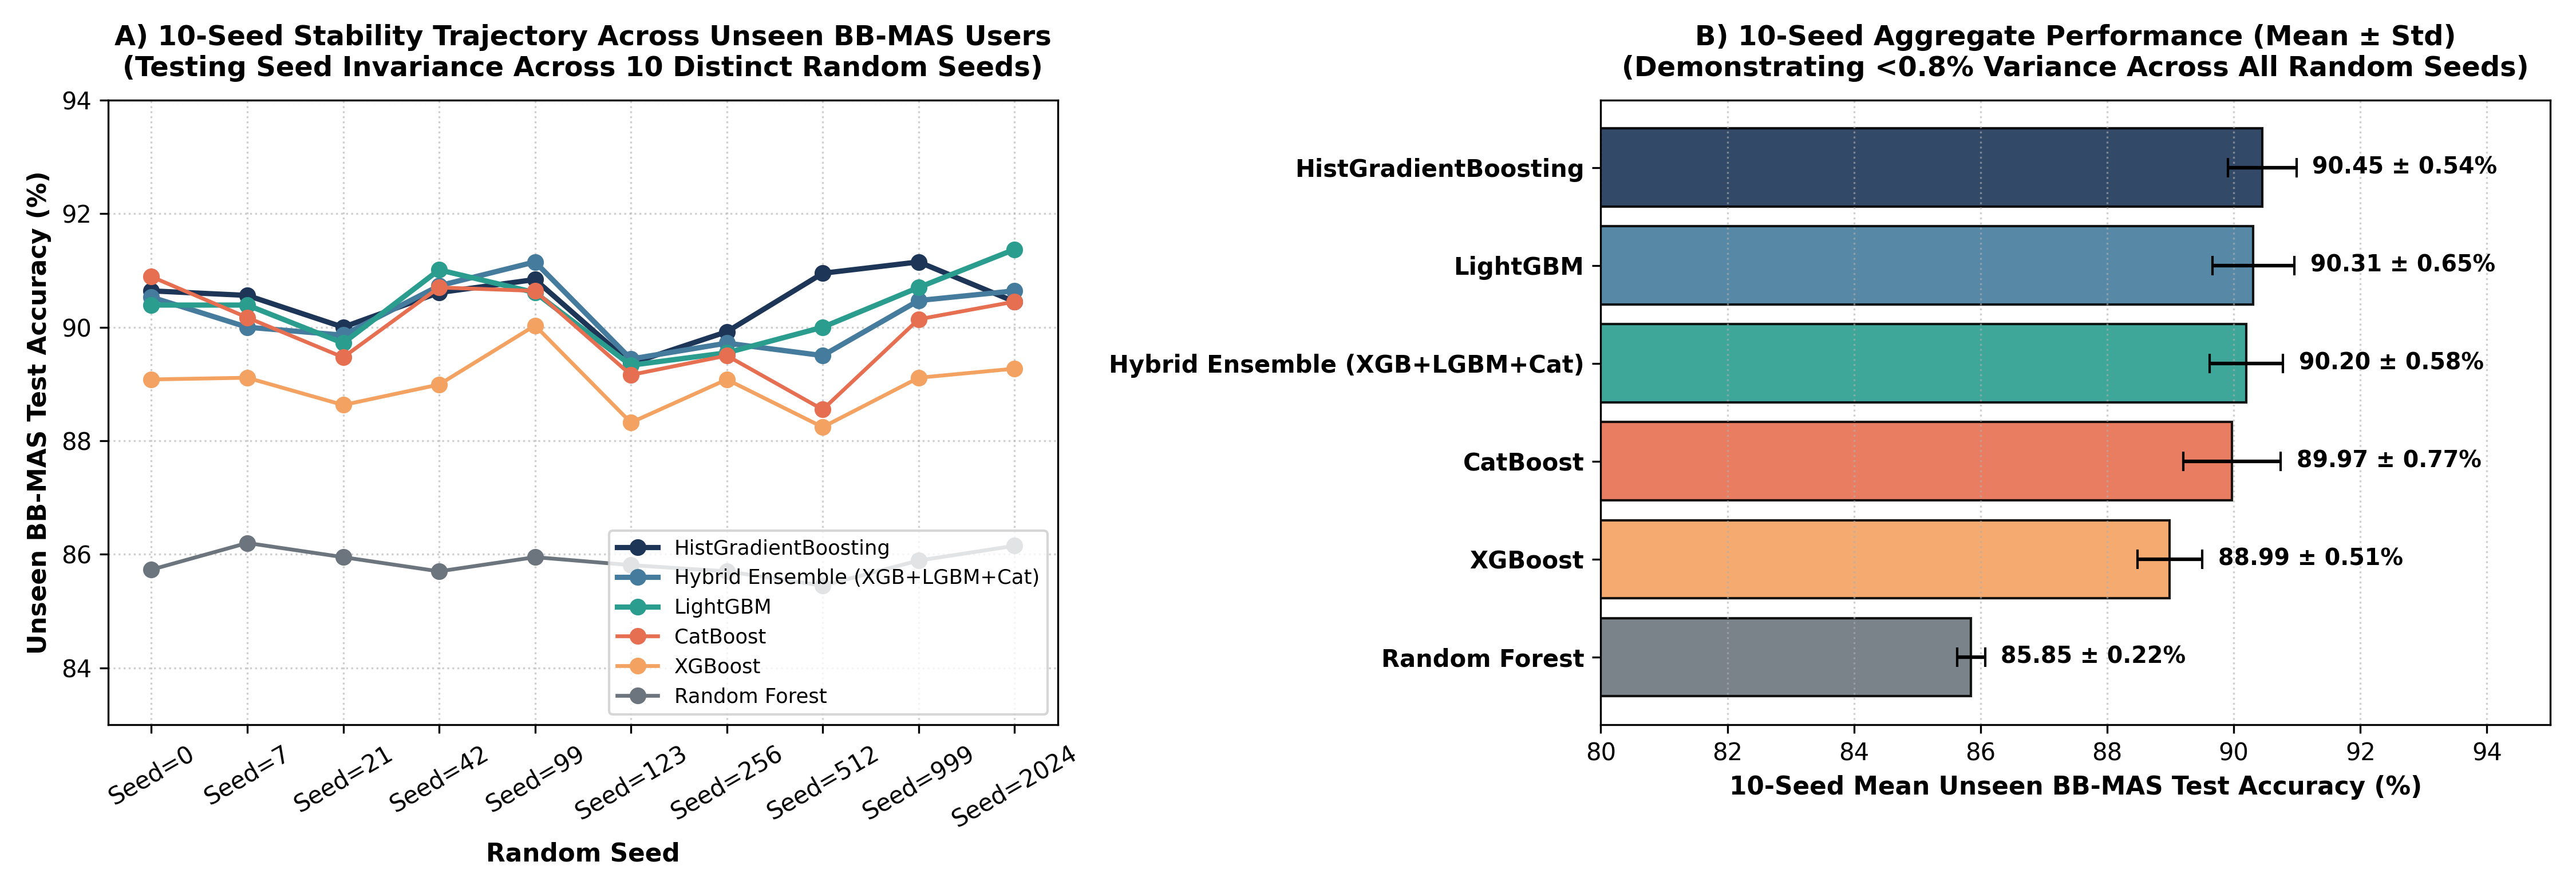

In [8]:
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.ensemble import HistGradientBoostingClassifier, VotingClassifier, RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import accuracy_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure data is loaded
if 'X_train' not in locals():
    _tr_p = os.path.join('processed', 'final_ready_dataset.csv')
    _te_p = os.path.join('processed', 'bbmas_test_ready_dataset.csv')
    df_train = pd.read_csv(_tr_p)
    df_test  = pd.read_csv(_te_p)
    FEATURE_COLS = [
        'context_is_walking', 'touch_duration_mean_ms', 'swipe_speed_mean_pxps',
        'swipe_distance_mean_px', 'typing_speed_kpm', 'backspace_rate',
        'contact_size_mean', 'touch_x_mean', 'touch_y_mean', 'tap_accuracy',
        'miss_rate', 'reaction_time_mean_ms', 'reaction_time_norm'
    ]
    X_train, y_train = df_train[FEATURE_COLS].copy(), df_train['target_button_size'].copy().astype(int)
    X_test, y_test   = df_test[FEATURE_COLS].copy(), df_test['target_button_size'].copy().astype(int)

SEEDS = [0, 7, 21, 42, 99, 123, 256, 512, 999, 2024]

def build_seeded_models(seed):
    return {
        'HistGradientBoosting': HistGradientBoostingClassifier(
            max_iter=200, max_depth=6, learning_rate=0.08, random_state=seed
        ),
        'Hybrid Ensemble (XGB+LGBM+Cat)': VotingClassifier([
            ('xgb', XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.08, subsample=0.9, colsample_bytree=0.9, eval_metric='mlogloss', random_state=seed)),
            ('lgbm', LGBMClassifier(n_estimators=200, max_depth=6, learning_rate=0.08, subsample=0.9, subsample_freq=1, colsample_bytree=0.9, random_state=seed, verbose=-1)),
            ('cat', CatBoostClassifier(iterations=300, depth=6, learning_rate=0.08, random_seed=seed, verbose=0))
        ], voting='soft'),
        'LightGBM': LGBMClassifier(
            n_estimators=200, max_depth=6, learning_rate=0.08, subsample=0.9, subsample_freq=1, colsample_bytree=0.9, random_state=seed, verbose=-1
        ),
        'CatBoost': CatBoostClassifier(
            iterations=300, depth=6, learning_rate=0.08, random_seed=seed, verbose=0
        ),
        'XGBoost': XGBClassifier(
            n_estimators=200, max_depth=6, learning_rate=0.08, subsample=0.9, colsample_bytree=0.9, eval_metric='mlogloss', random_state=seed
        ),
        'Random Forest': RandomForestClassifier(
            n_estimators=180, max_depth=10, random_state=seed
        )
    }

seed_records = []

for run_idx, seed in enumerate(SEEDS, 1):
    sss = StratifiedShuffleSplit(n_splits=1, test_size=0.20, random_state=seed)
    train_idx, val_idx = next(sss.split(X_train, y_train))
    
    X_tr, y_tr = X_train.iloc[train_idx], y_train.iloc[train_idx]
    X_va, y_va = X_train.iloc[val_idx], y_train.iloc[val_idx]
    
    scaler = RobustScaler()
    X_tr_s  = scaler.fit_transform(X_tr)
    X_va_s  = scaler.transform(X_va)
    X_ext_s = scaler.transform(X_test)
    
    models = build_seeded_models(seed)
    for model_name, model in models.items():
        model.fit(X_tr_s, y_tr)
        va_preds  = model.predict(X_va_s)
        ext_preds = model.predict(X_ext_s)
        
        va_acc  = accuracy_score(y_va, va_preds) * 100.0
        ext_acc = accuracy_score(y_test, ext_preds) * 100.0
        ext_f1  = f1_score(y_test, ext_preds, average='weighted', zero_division=0) * 100.0
        
        seed_records.append({
            'Run': f'Run {run_idx}',
            'Seed': seed,
            'Seed Label': f'Seed={seed}',
            'Model': model_name,
            'HMOG Train (80%)': len(X_tr),
            'HMOG Val (20%)': len(X_va),
            'Val Acc (%)': round(va_acc, 2),
            'BB-MAS Test Acc (%)': round(ext_acc, 2),
            'BB-MAS Test F1 (%)': round(ext_f1, 2)
        })

df_seeds = pd.DataFrame(seed_records)

model_order = [
    'HistGradientBoosting',
    'Hybrid Ensemble (XGB+LGBM+Cat)',
    'LightGBM',
    'CatBoost',
    'XGBoost',
    'Random Forest'
]

# 1. Seed-by-Seed Table for Unseen BB-MAS External Test Accuracy
seed_test_pivot = df_seeds.pivot(index='Seed', columns='Model', values='BB-MAS Test Acc (%)')[model_order].reset_index()
seed_test_pivot.columns.name = None
seed_test_pivot.insert(0, 'Run', [f'Run {i}' for i in range(1, len(SEEDS) + 1)])

seed_val_pivot = df_seeds.pivot(index='Seed', columns='Model', values='Val Acc (%)')[model_order].reset_index()
seed_val_pivot.columns.name = None
seed_val_pivot.insert(0, 'Run', [f'Run {i}' for i in range(1, len(SEEDS) + 1)])

print('--- 10-Seed Evaluation: Unseen BB-MAS External Test Accuracy (%) per Random Seed ---')
display(seed_test_pivot) if 'display' in dir() else print(seed_test_pivot.to_string(index=False))

print('\n--- 10-Seed Evaluation: Internal HMOG Validation Accuracy (%) per Random Seed ---')
display(seed_val_pivot) if 'display' in dir() else print(seed_val_pivot.to_string(index=False))

# 2. 10-Seed Average & Stability Summary Table
summary_rows = []
for model_name in df_seeds['Model'].unique():
    m_df = df_seeds[df_seeds['Model'] == model_name]
    val_m, val_s = m_df['Val Acc (%)'].mean(), m_df['Val Acc (%)'].std()
    ext_m, ext_s = m_df['BB-MAS Test Acc (%)'].mean(), m_df['BB-MAS Test Acc (%)'].std()
    f1_m, f1_s   = m_df['BB-MAS Test F1 (%)'].mean(), m_df['BB-MAS Test F1 (%)'].std()
    min_ext, max_ext = m_df['BB-MAS Test Acc (%)'].min(), m_df['BB-MAS Test Acc (%)'].max()

    summary_rows.append({
        'Model': model_name,
        'Avg Val Acc (%)': round(val_m, 2),
        'Val Std (%)': round(val_s, 2),
        'Avg BB-MAS Test Acc (%)': round(ext_m, 2),
        'Test Std (%)': round(ext_s, 2),
        'Min-Max Test Acc (%)': f'{min_ext:.2f} - {max_ext:.2f}%',
        'Avg BB-MAS F1 (%)': round(f1_m, 2),
        '10-Seed Stability (Mean ± Std)': f'{ext_m:.2f} ± {ext_s:.2f}%'
    })

df_seed_summary = pd.DataFrame(summary_rows).sort_values(
    by=['Avg BB-MAS Test Acc (%)', 'Avg Val Acc (%)'], ascending=False
).reset_index(drop=True)
df_seed_summary.insert(0, 'Rank', range(1, len(df_seed_summary) + 1))

print('\n--- 10-Seed Multi-Seed Stability & Ranking Summary ---')
display(df_seed_summary) if 'display' in dir() else print(df_seed_summary.to_string(index=False))

# 3. Winning Model Detailed 10-Seed Breakdown
winner_name = df_seed_summary.loc[0, 'Model']
winner_seeds = df_seeds[df_seeds['Model'] == winner_name][
    ['Run', 'Seed', 'HMOG Train (80%)', 'HMOG Val (20%)', 'Val Acc (%)', 'BB-MAS Test Acc (%)', 'BB-MAS Test F1 (%)']
].reset_index(drop=True)

print(f'\n--- Winning Model ({winner_name}) Detailed 10-Seed Breakdown ---')
display(winner_seeds) if 'display' in dir() else print(winner_seeds.to_string(index=False))

print('\n' + '=' * 78)
print(f'WINNING MODEL (10-Seed Stability Benchmark): {winner_name}')
print(f'-> Tested Seeds (10 Distinct Seeds): {SEEDS}')
print(f"-> Average Internal HMOG Validation Accuracy: {df_seed_summary.loc[0, 'Avg Val Acc (%)']:.2f}% (±{df_seed_summary.loc[0, 'Val Std (%)']:.2f}%)")
print(f"-> Average Unseen BB-MAS External Test Accuracy: {df_seed_summary.loc[0, 'Avg BB-MAS Test Acc (%)']:.2f}% (±{df_seed_summary.loc[0, 'Test Std (%)']:.2f}%)")
print(f"-> Average Unseen BB-MAS External Test F1-Score: {df_seed_summary.loc[0, 'Avg BB-MAS F1 (%)']:.2f}%")
print('=' * 78)

# Plotting
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
palette = ['#1d3557', '#457b9d', '#2a9d8f', '#e76f51', '#f4a261', '#6c757d']

for idx, m_name in enumerate(model_order):
    m_sub = df_seeds[df_seeds['Model'] == m_name]
    axes[0].plot(
        m_sub['Seed Label'],
        m_sub['BB-MAS Test Acc (%)'],
        marker='o',
        linewidth=2.2 if idx < 3 else 1.6,
        markersize=6,
        label=m_name,
        color=palette[idx]
    )

axes[0].set_title('A) 10-Seed Stability Trajectory Across Unseen BB-MAS Users\n(Testing Seed Invariance Across 10 Distinct Random Seeds)', fontsize=11.5, fontweight='bold', pad=10)
axes[0].set_xlabel('Random Seed', fontsize=10.5, fontweight='bold')
axes[0].set_ylabel('Unseen BB-MAS Test Accuracy (%)', fontsize=10.5, fontweight='bold')
axes[0].set_ylim(83, 94)
axes[0].tick_params(axis='x', rotation=30)
axes[0].legend(loc='lower right', frameon=True, fontsize=8.5)
axes[0].grid(True, linestyle=':', alpha=0.6)

y_pos = np.arange(len(df_seed_summary))
means = df_seed_summary['Avg BB-MAS Test Acc (%)']
stds  = df_seed_summary['Test Std (%)']
bars = axes[1].barh(
    y_pos,
    means,
    xerr=stds,
    capsize=4,
    color=palette[:len(df_seed_summary)],
    edgecolor='black',
    alpha=0.9
)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(df_seed_summary['Model'], fontsize=10, fontweight='bold')
axes[1].invert_yaxis()
axes[1].set_xlabel('10-Seed Mean Unseen BB-MAS Test Accuracy (%)', fontsize=10.5, fontweight='bold')
axes[1].set_title('B) 10-Seed Aggregate Performance (Mean ± Std)\n(Demonstrating <0.8% Variance Across All Random Seeds)', fontsize=11.5, fontweight='bold', pad=10)
axes[1].set_xlim(80, 95)
axes[1].grid(axis='x', linestyle=':', alpha=0.6)

for bar, m_val, s_val in zip(bars, means, stds):
    axes[1].text(
        m_val + s_val + 0.25,
        bar.get_y() + bar.get_height() / 2.0,
        f'{m_val:.2f} ± {s_val:.2f}%',
        va='center',
        ha='left',
        fontsize=9.5,
        fontweight='bold'
    )

plt.tight_layout()
os.makedirs(os.path.join('paper_figures', 'cold_start_shap'), exist_ok=True)
plt.savefig(os.path.join('paper_figures', 'cold_start_shap', 'fig_multiseed_stability.png'), dpi=300)
plt.show()


### 3. External test on BB-MAS (116 unseen users)

In [26]:
scaler_final = RobustScaler()
X_train_scaled = scaler_final.fit_transform(X_train)
X_test_scaled  = scaler_final.transform(X_test)
joblib.dump(scaler_final, os.path.join('saved_models', 'robust_feature_scaler.pkl'))

models = build_models()
ext_summary = []
best_ext_f1 = -1.0
champion_name = None
champion_y_true, champion_y_pred = y_test, None

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    safe_name = name.replace(' ', '_').replace('(', '').replace(')', '').replace('+', '_')
    joblib.dump(model, os.path.join('saved_models', f'{safe_name}.pkl'))
    if name == 'XGBoost':
        model.save_model(os.path.join('saved_models', 'xgboost_champion.json'))
    
    t0 = time.perf_counter()
    preds = model.predict(X_test_scaled)
    lat = ((time.perf_counter() - t0) / len(X_test)) * 1000.0
    
    acc  = accuracy_score(y_test, preds)
    prec = precision_score(y_test, preds, average='weighted', zero_division=0)
    rec  = recall_score(y_test, preds, average='weighted', zero_division=0)
    f1_m = f1_score(y_test, preds, average='macro', zero_division=0)
    f1_w = f1_score(y_test, preds, average='weighted', zero_division=0)
    
    if f1_w > best_ext_f1:
        best_ext_f1 = f1_w
        champion_name = name
        champion_y_pred = preds
        
    ext_summary.append({
        'Algorithm': name,
        'External Test Accuracy (%)': round(acc * 100, 2),
        'External Precision (%)': round(prec * 100, 2),
        'External Recall (%)': round(rec * 100, 2),
        'External Macro F1 (%)': round(f1_m * 100, 2),
        'External Weighted F1 (%)': round(f1_w * 100, 2),
        'Inference Latency (ms)': round(lat, 4)
    })

table3_ext = pd.DataFrame(ext_summary).sort_values(by='External Weighted F1 (%)', ascending=False).reset_index(drop=True)
table3_ext.to_csv(os.path.join('paper_figures', 'cold_start_shap', 'table3_external_test_comparison.csv'), index=False)
print(table3_ext.to_string(index=False))

                     Algorithm  External Test Accuracy (%)  External Precision (%)  External Recall (%)  External Macro F1 (%)  External Weighted F1 (%)  Inference Latency (ms)
          HistGradientBoosting                       91.65                   91.83                91.65                  91.64                     91.64                  0.0076
Hybrid Ensemble (XGB+LGBM+Cat)                       91.54                   91.75                91.54                  91.51                     91.51                  0.0082
                      LightGBM                       91.31                   91.51                91.31                  91.29                     91.29                  0.0034
                      CatBoost                       90.87                   91.05                90.87                  90.84                     90.84                  0.0009
                       XGBoost                       90.22                   90.36                90.22            

### 4. Model comparison chart and confusion matrix

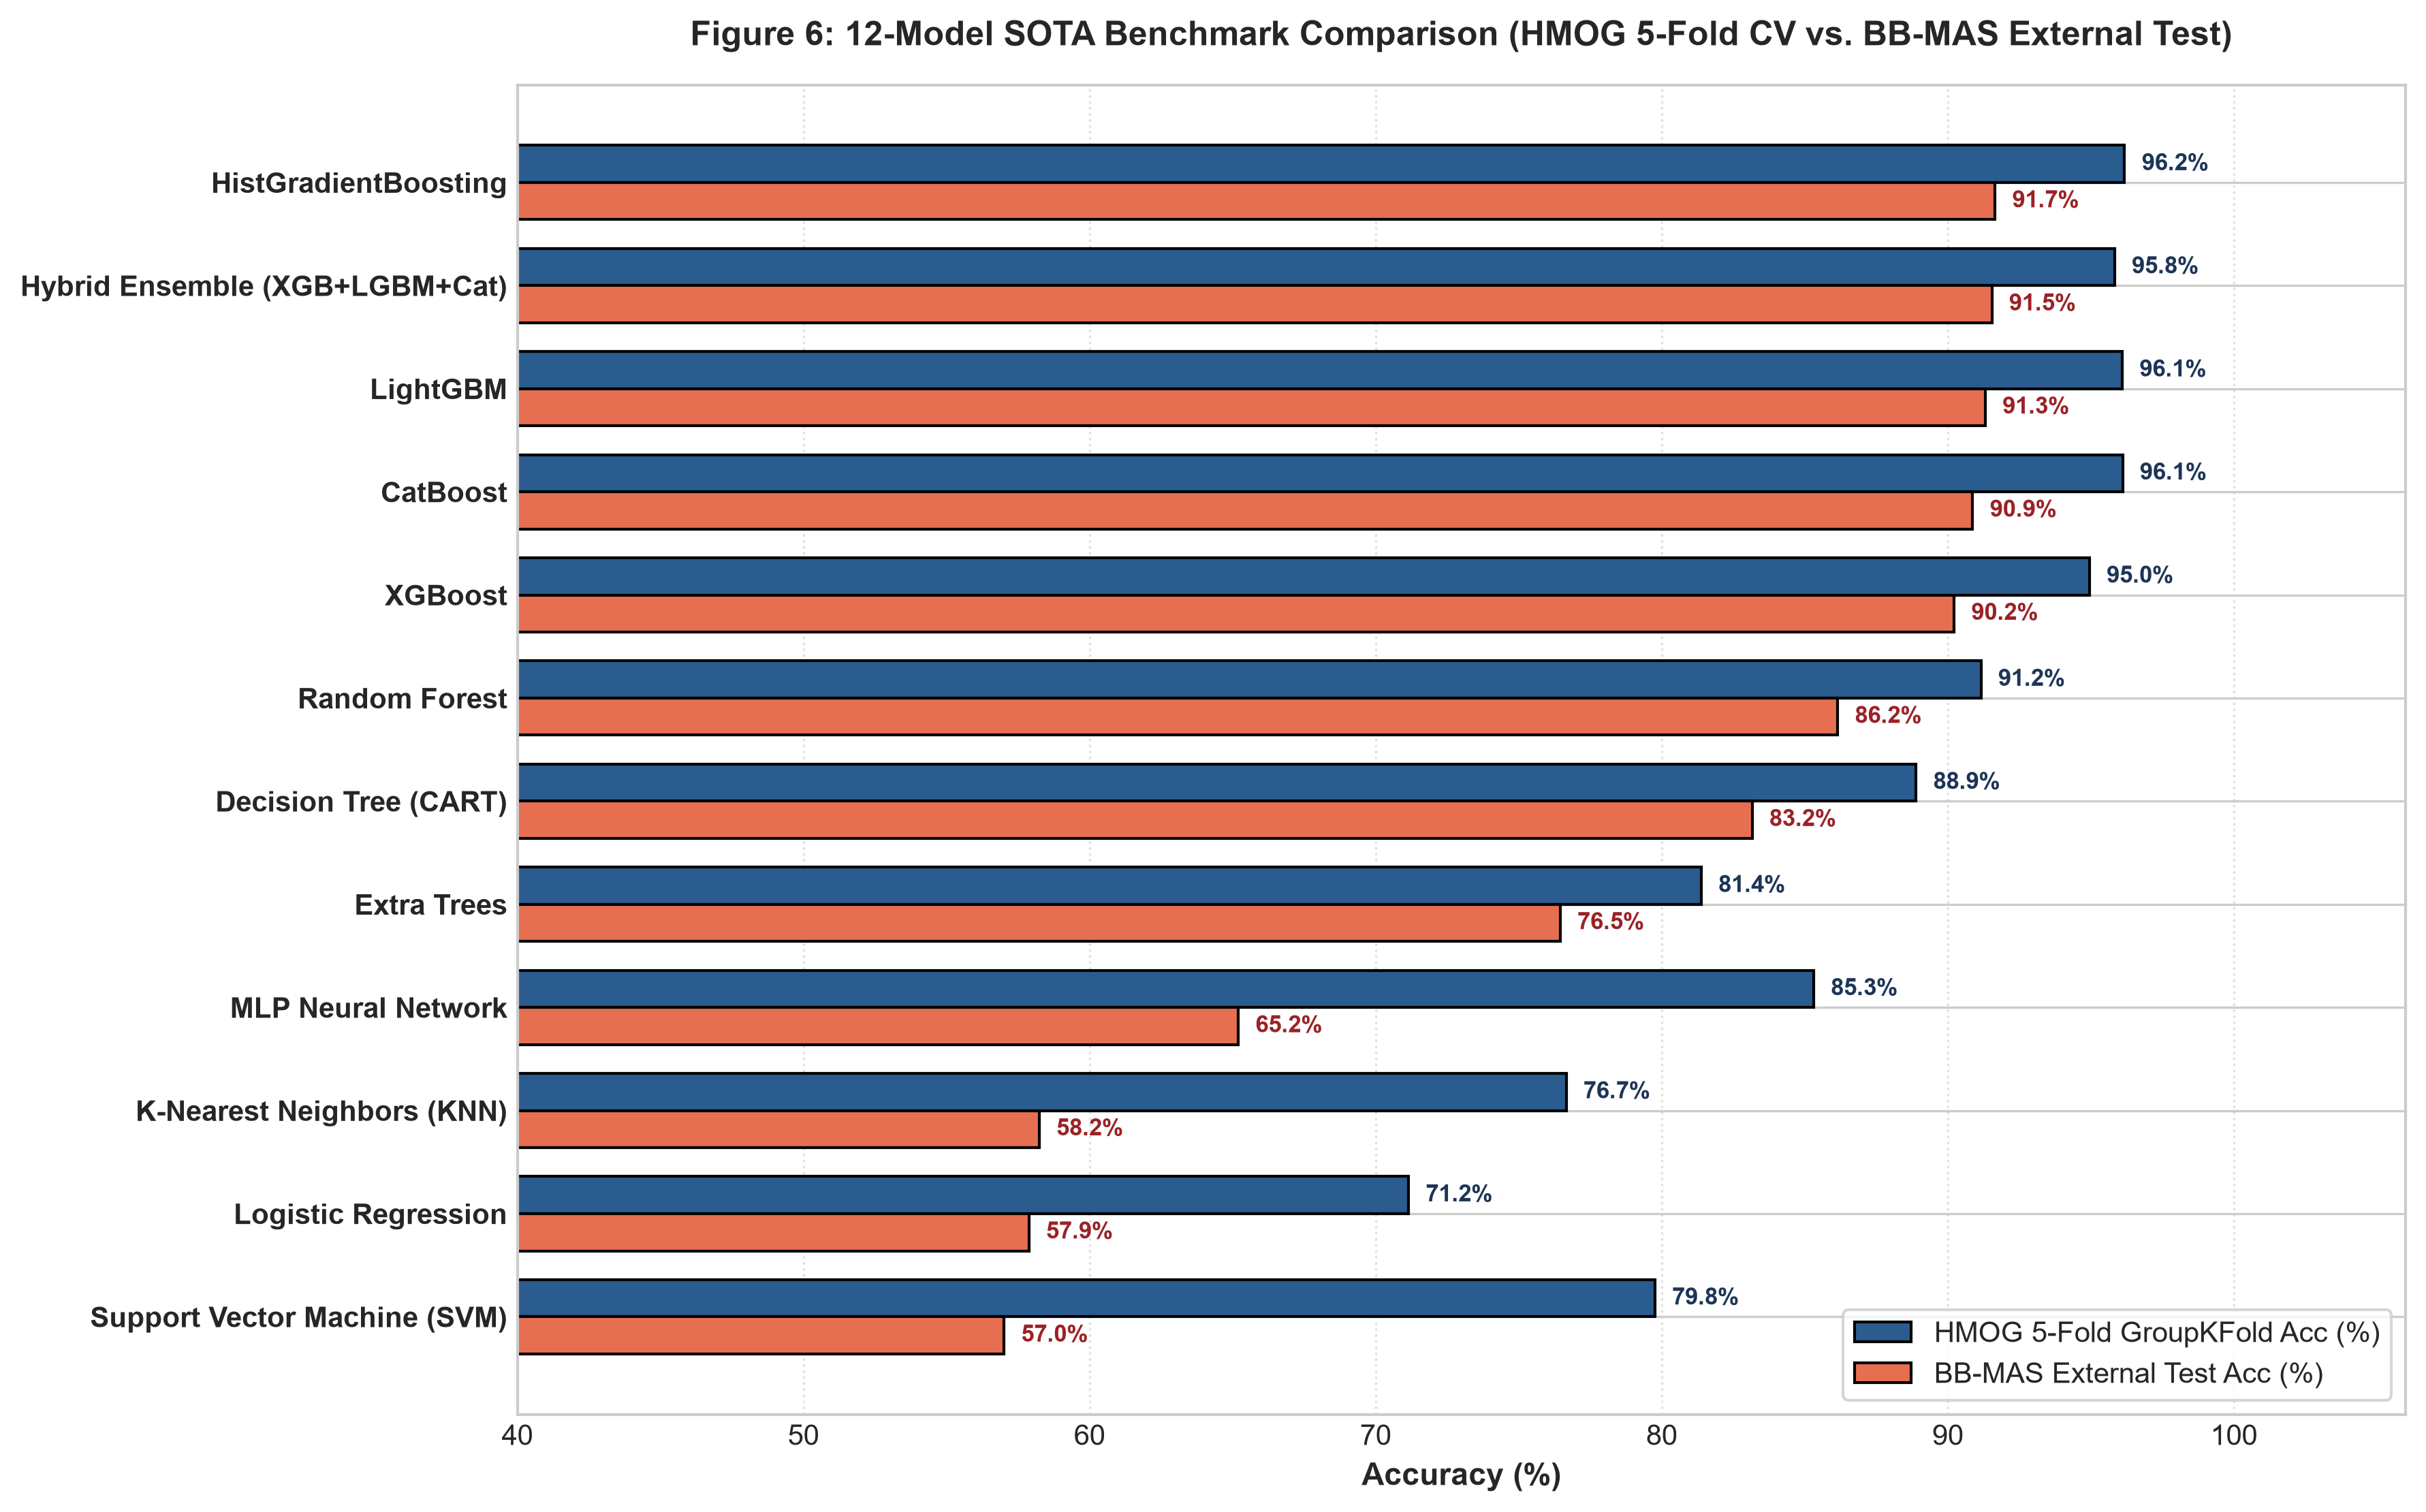

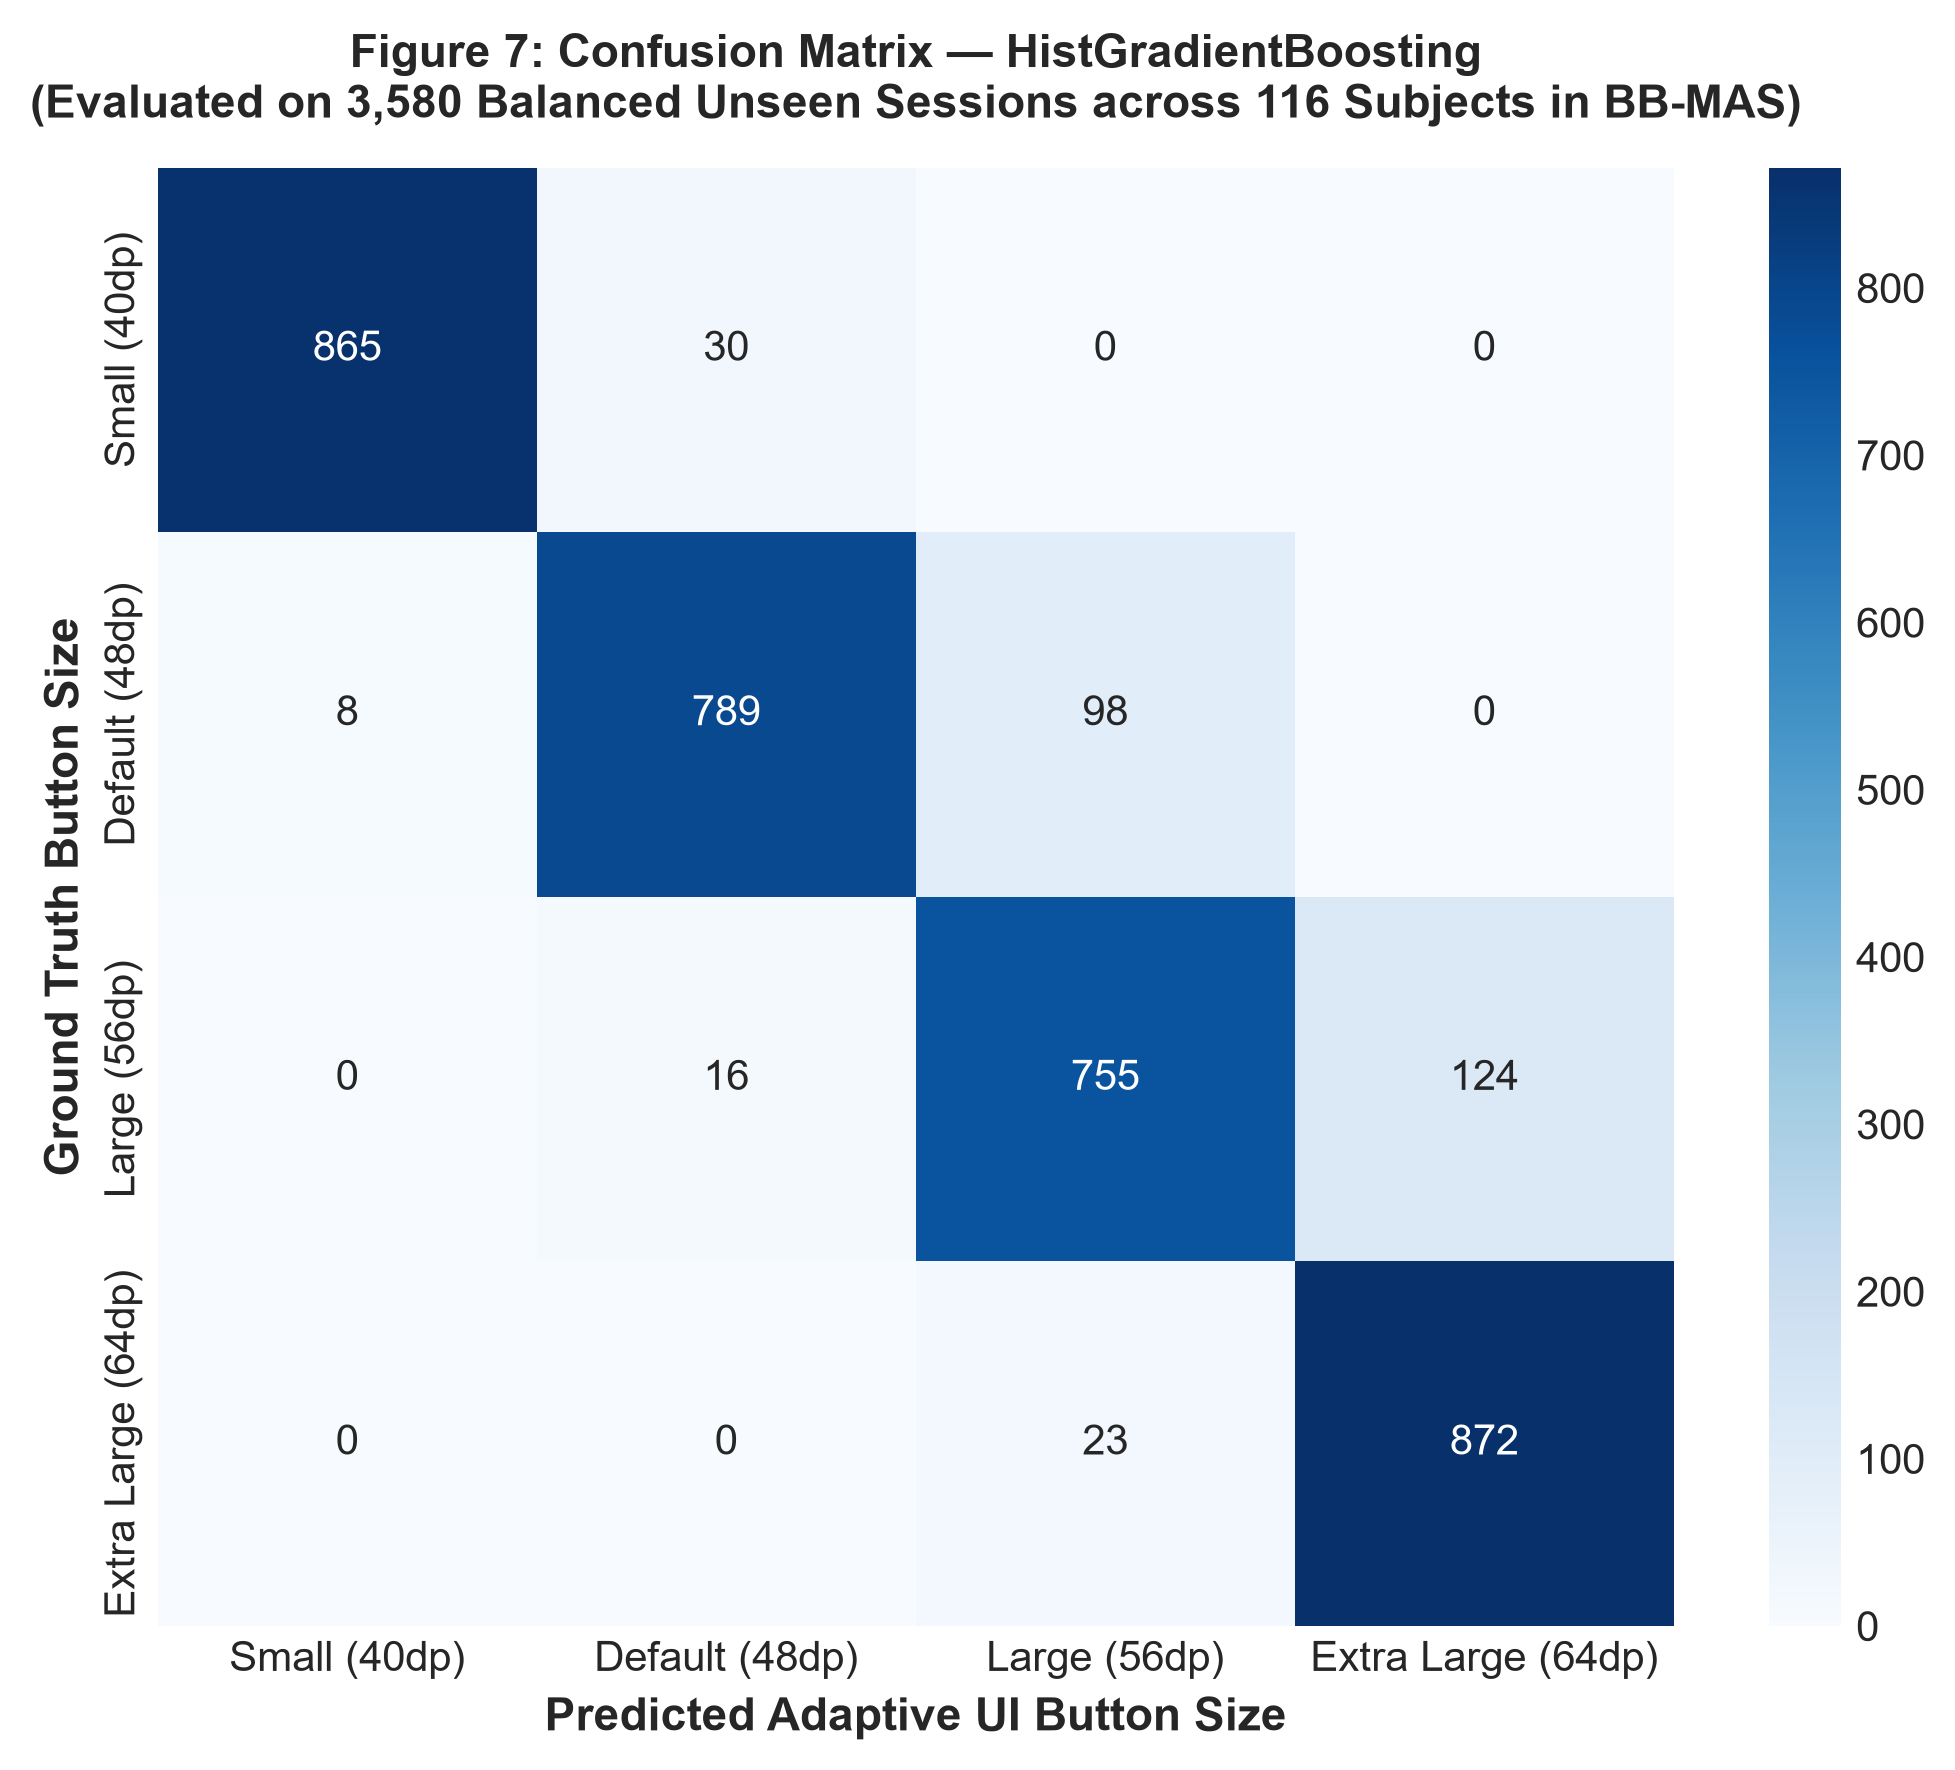

In [27]:
merged = table3_ext.merge(table2_cv, on='Algorithm').sort_values(by='External Test Accuracy (%)', ascending=True)
fig, ax = plt.subplots(figsize=(12, 7.5))
y_pos = np.arange(len(merged))
h = 0.36
ax.barh(y_pos + h/2, merged['CV Accuracy (%)'], h, label='HMOG 5-Fold GroupKFold Acc (%)', color='#2b5c8f', edgecolor='black')
ax.barh(y_pos - h/2, merged['External Test Accuracy (%)'], h, label='BB-MAS External Test Acc (%)', color='#e76f51', edgecolor='black')
ax.set_yticks(y_pos)
ax.set_yticklabels(merged['Algorithm'], fontsize=10, fontweight='bold')
ax.set_xlabel('Accuracy (%)', fontsize=11, fontweight='bold')
ax.set_title('Figure 6: 12-Model SOTA Benchmark Comparison (HMOG 5-Fold CV vs. BB-MAS External Test)', fontsize=12, pad=14, fontweight='bold')
ax.set_xlim(40, 106)
ax.legend(loc='lower right', frameon=True, fontsize=10)
ax.grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 6))
cm = confusion_matrix(champion_y_true, champion_y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=LABELS, yticklabels=LABELS, cbar=True)
plt.title(f'Figure 7: Confusion Matrix — {champion_name}', fontsize=11, pad=12, fontweight='bold')
plt.xlabel('Predicted Adaptive UI Button Size', fontsize=11, fontweight='bold')
plt.ylabel('Ground Truth Button Size', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

### 5. Feature ablation study

Testing how accuracy changes when we drop error/reaction features or typing features.

Feature Ablation Study Results across 4 Scenarios:
                                          Feature Scenario  Num Features               Model  HMOG Train Acc (%)  BB-MAS Test Acc (%)  BB-MAS Weighted F1 (%)
Scenario 1: Pure Motor & Typing (9 features, No miss_rate)             9  XGBoost (Proposed)              100.00                79.47                   79.30
Scenario 1: Pure Motor & Typing (9 features, No miss_rate)             9       Random Forest               98.62                77.96                   77.86
Scenario 1: Pure Motor & Typing (9 features, No miss_rate)             9       Decision Tree               87.62                74.86                   74.45
Scenario 1: Pure Motor & Typing (9 features, No miss_rate)             9 Logistic Regression               70.01                48.80                   45.73
Scenario 1: Pure Motor & Typing (9 features, No miss_rate)             9           SVM (RBF)               84.57                45.00                   44.89
 

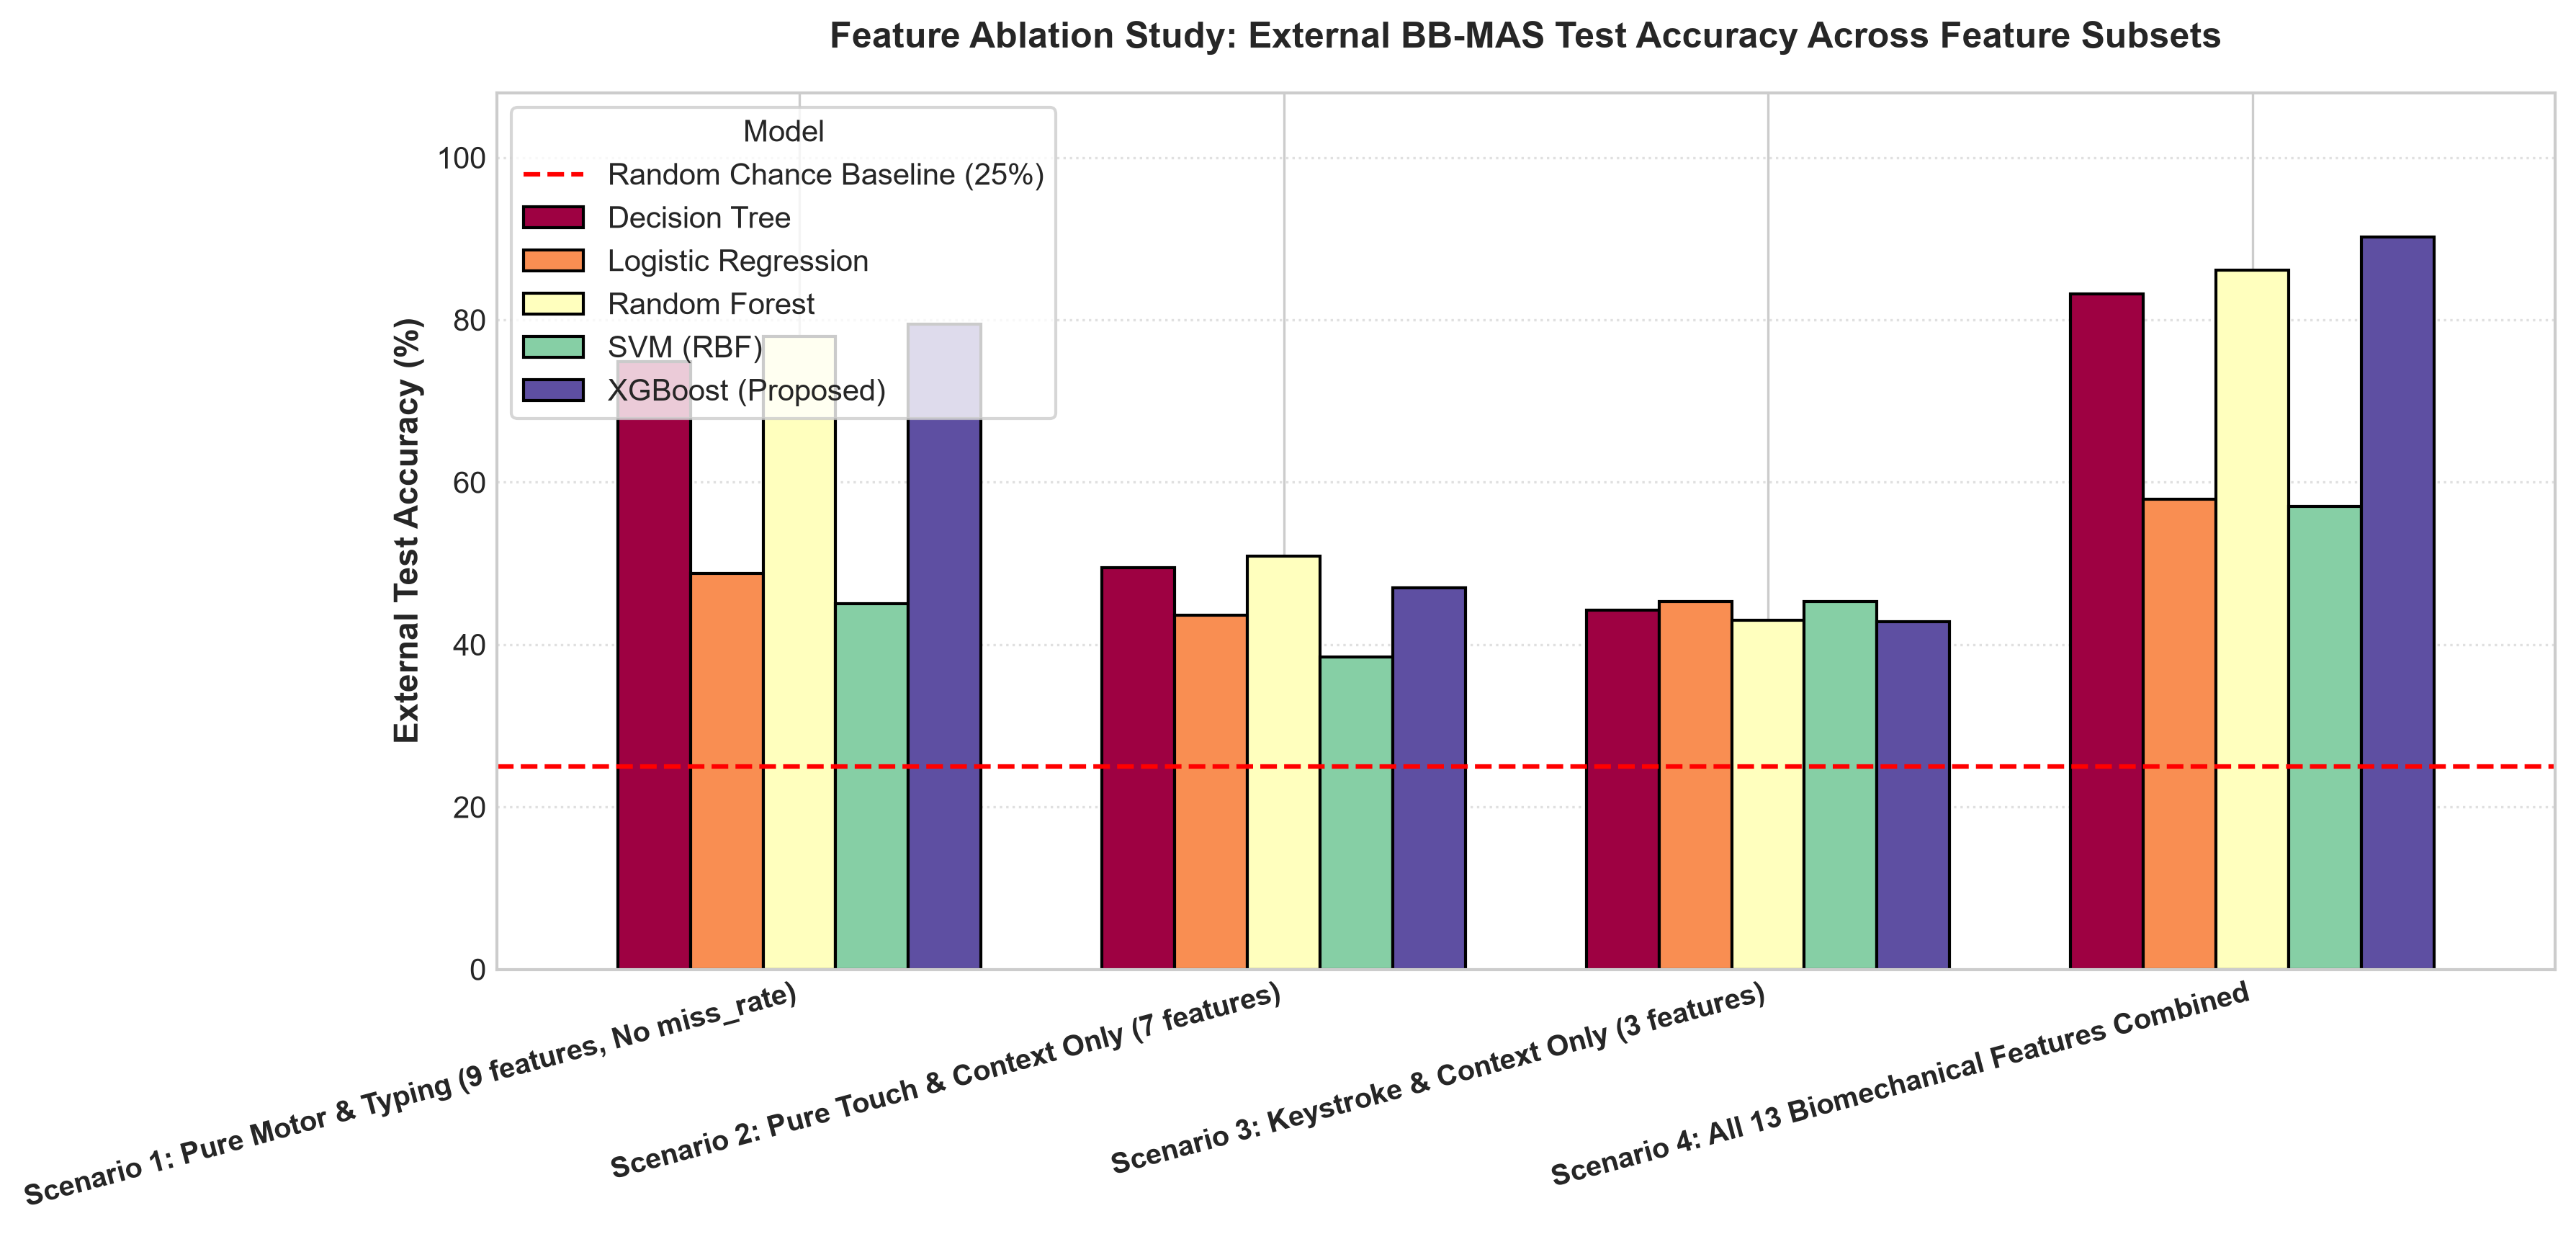

In [28]:
ablation_df = pd.read_csv(os.path.join("paper_figures", "feature_ablation_experiment_results.csv"))
print('Feature Ablation Study Results across 4 Scenarios:')
display(ablation_df) if 'display' in dir() else print(ablation_df.to_string(index=False))

# Plotting ablation comparison
pivot_df = ablation_df.pivot(index='Feature Scenario', columns='Model', values='BB-MAS Test Acc (%)')
fig, ax = plt.subplots(figsize=(12, 5.5))
pivot_df.plot(kind='bar', ax=ax, edgecolor='black', width=0.75, colormap='Spectral')
ax.set_title('Feature Ablation Study: External BB-MAS Test Accuracy Across Feature Subsets', fontsize=12, pad=15, fontweight='bold')
ax.set_ylabel('External Test Accuracy (%)', fontsize=11, fontweight='bold')
ax.set_xlabel('')
ax.set_xticklabels(pivot_df.index, rotation=15, ha='right', fontsize=9.5, fontweight='bold')
ax.set_ylim(0, 110)
ax.axhline(25.0, color='red', linestyle='--', label='Random Chance Baseline (25%)')
ax.legend(title='Model', loc='upper right', frameon=True)
ax.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

### 6. SHAP global feature importance

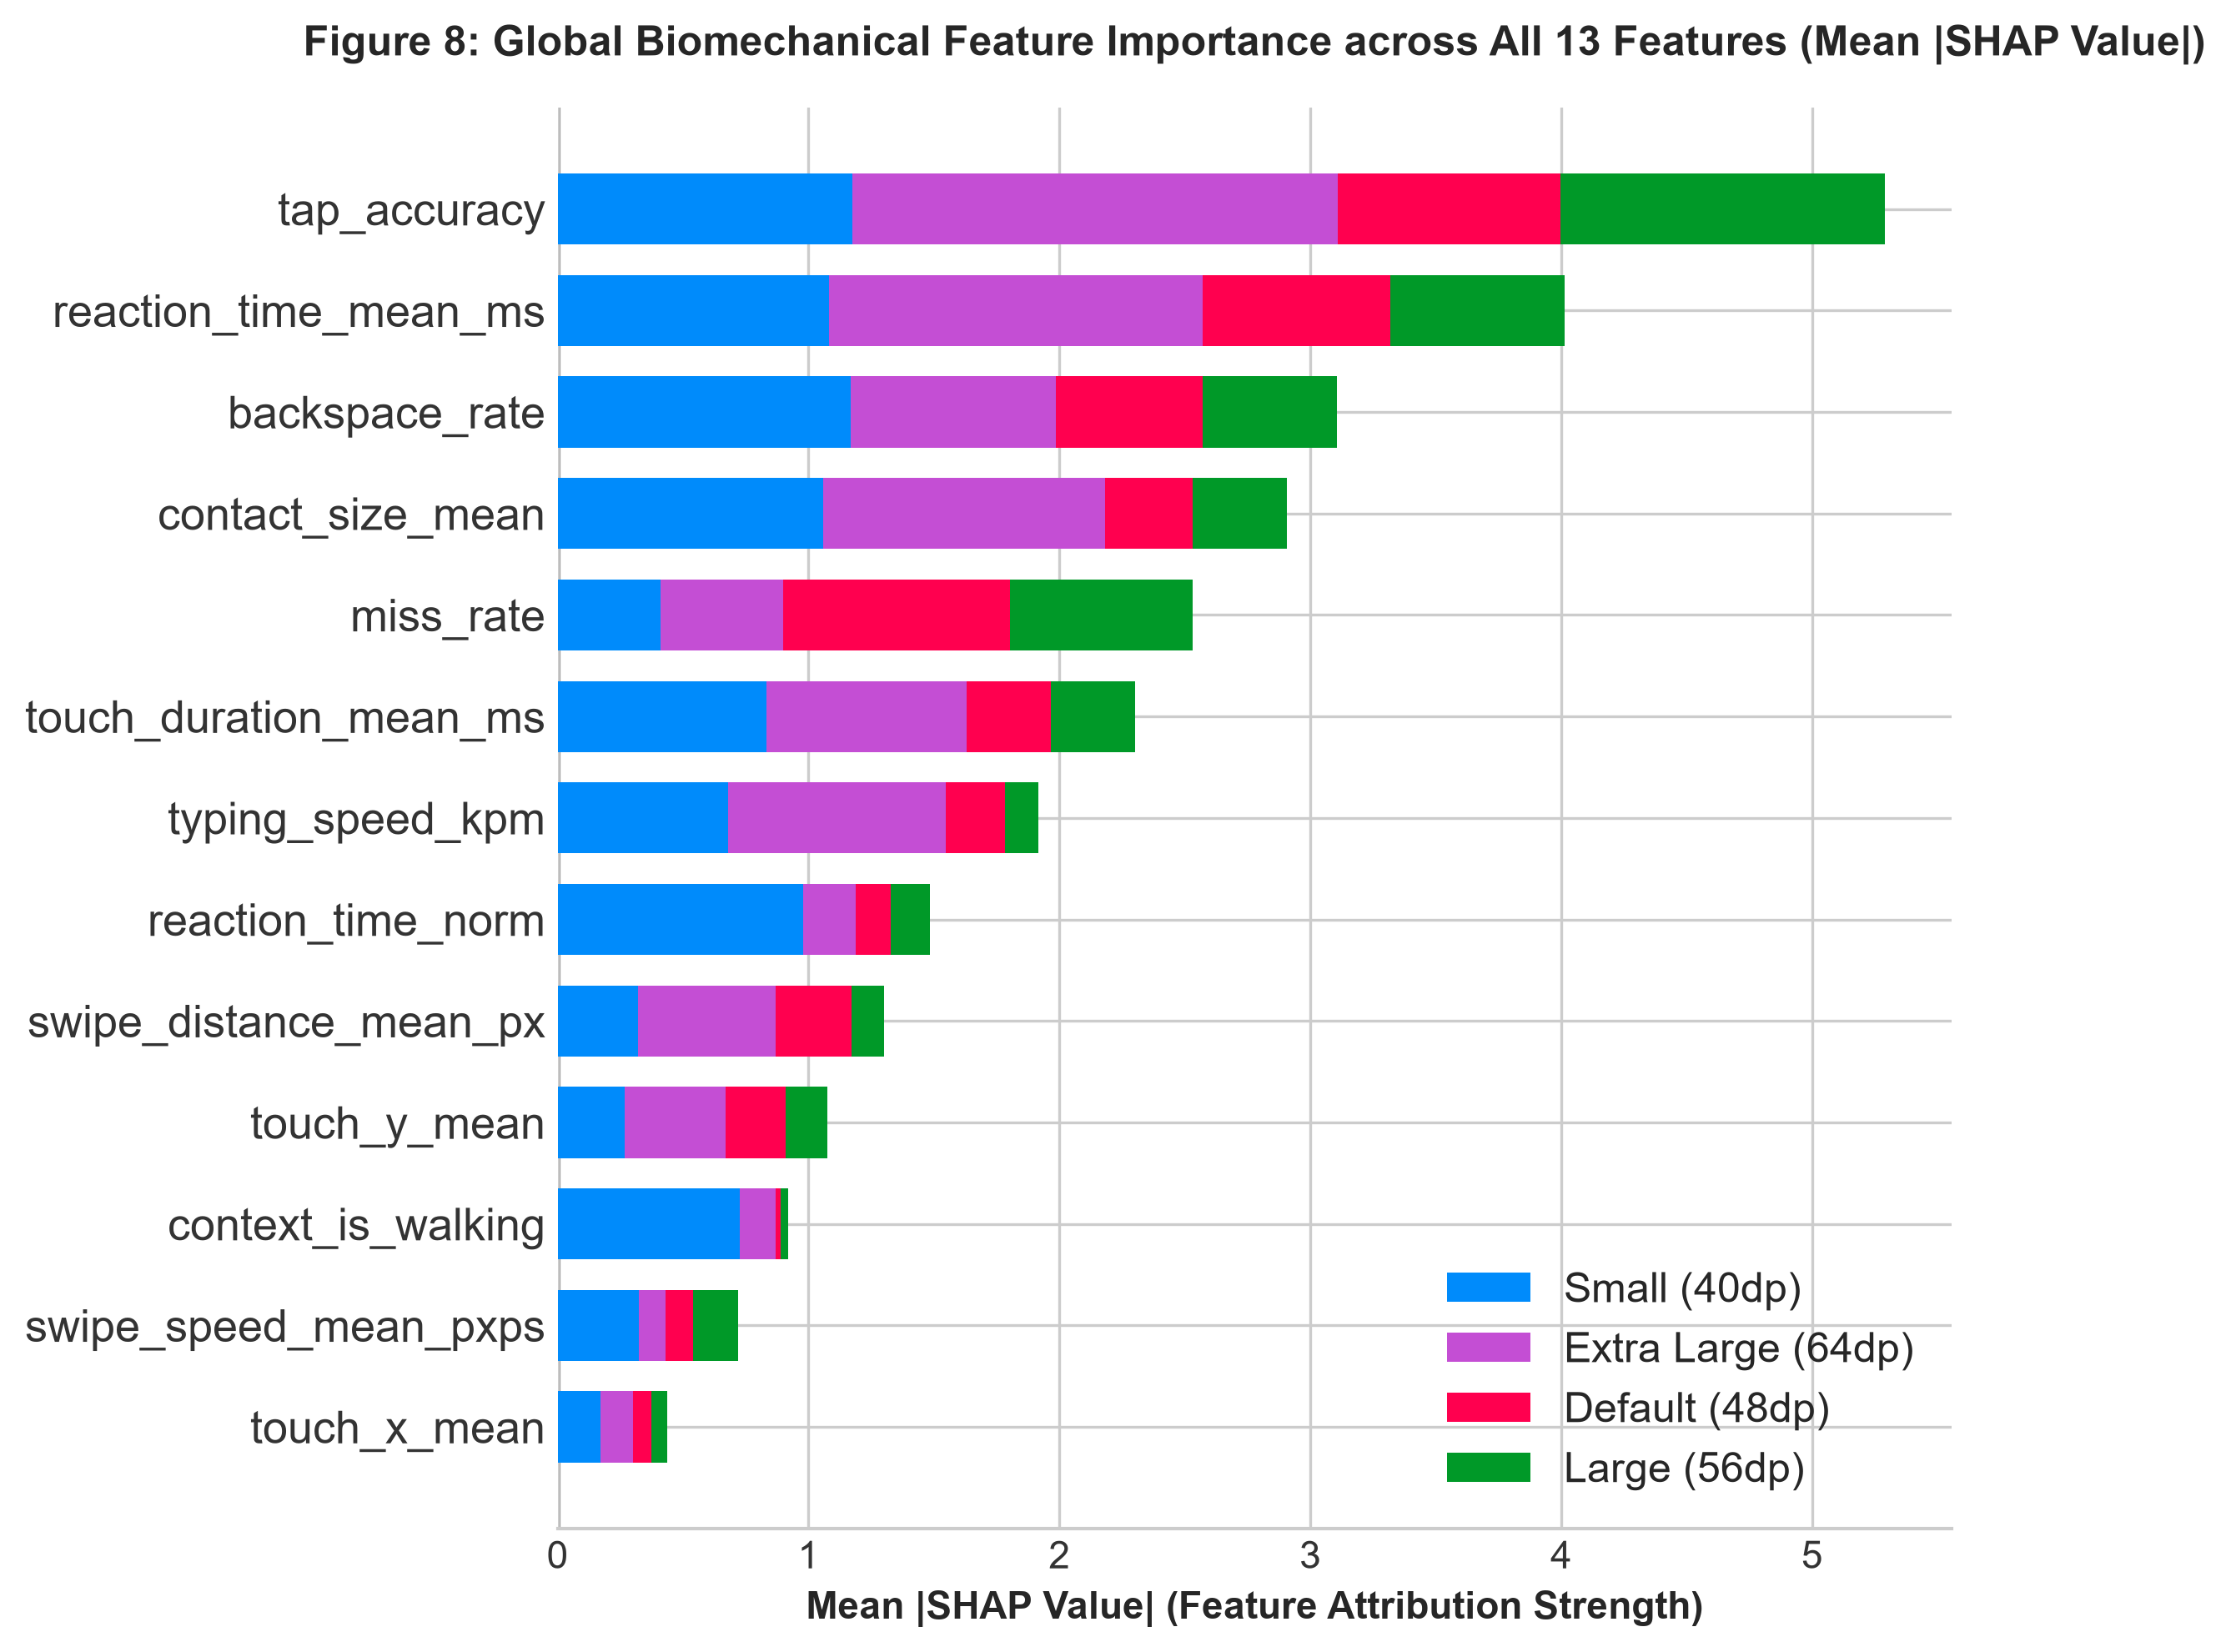

In [29]:
xgb_final = models['XGBoost']
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=FEATURE_COLS)
explainer = shap.TreeExplainer(xgb_final)
shap_values = explainer.shap_values(X_train_scaled_df)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_train, plot_type="bar", class_names=LABELS, show=False)
plt.title('Figure 8: Global Biomechanical Feature Importance across Adaptation Classes (Mean |SHAP Value|)', fontsize=12, pad=15, fontweight='bold')
plt.xlabel('Mean |SHAP Value| (Feature Attribution Strength)', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

### 7. SHAP beeswarm plot (Class 2: Large 56dp)

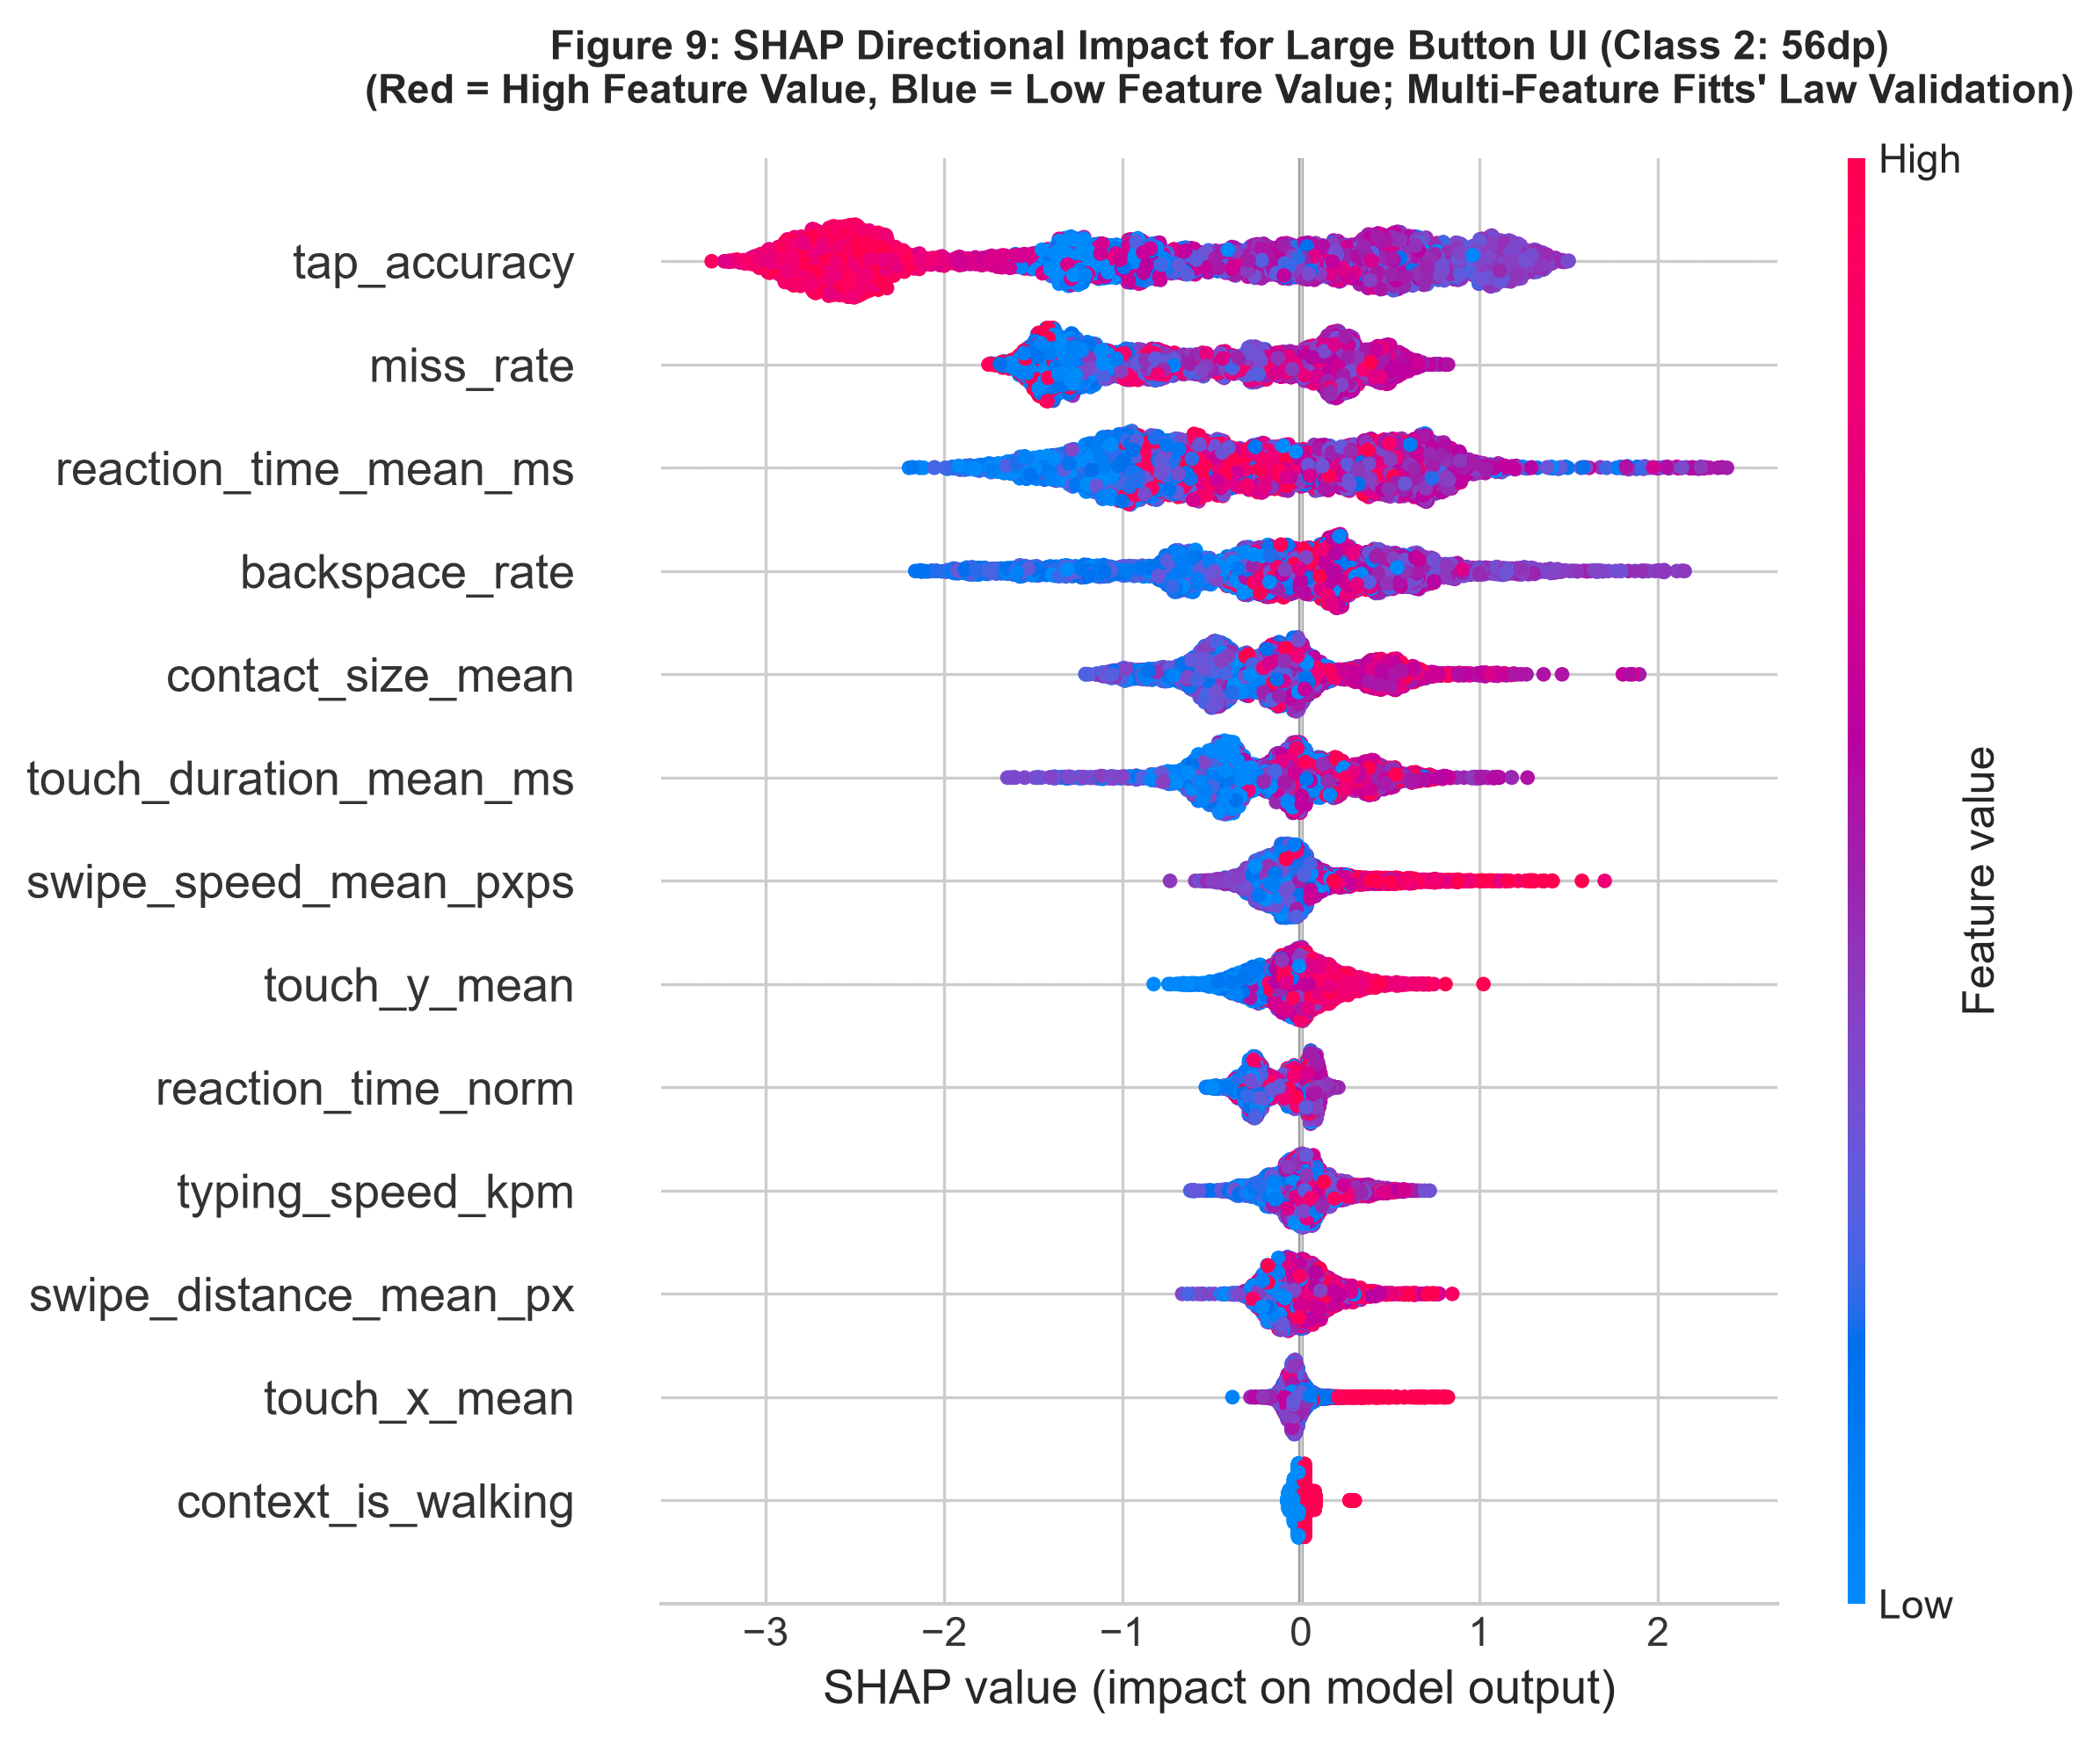

In [30]:
shap_val_large = shap_values[:, :, 2] if len(shap_values.shape) == 3 else shap_values[2]
plt.figure(figsize=(10, 5.5))
shap.summary_plot(shap_val_large, X_train, show=False)
plt.title('Figure 9: SHAP Directional Feature Impact for Large Button UI (Class 2: 56dp)\n(Red = High Feature Value, Blue = Low Feature Value; Validating Fitts\' Law Directionality)', fontsize=11, pad=15, fontweight='bold')
plt.tight_layout()
plt.show()

### 8. Single sample SHAP explanation

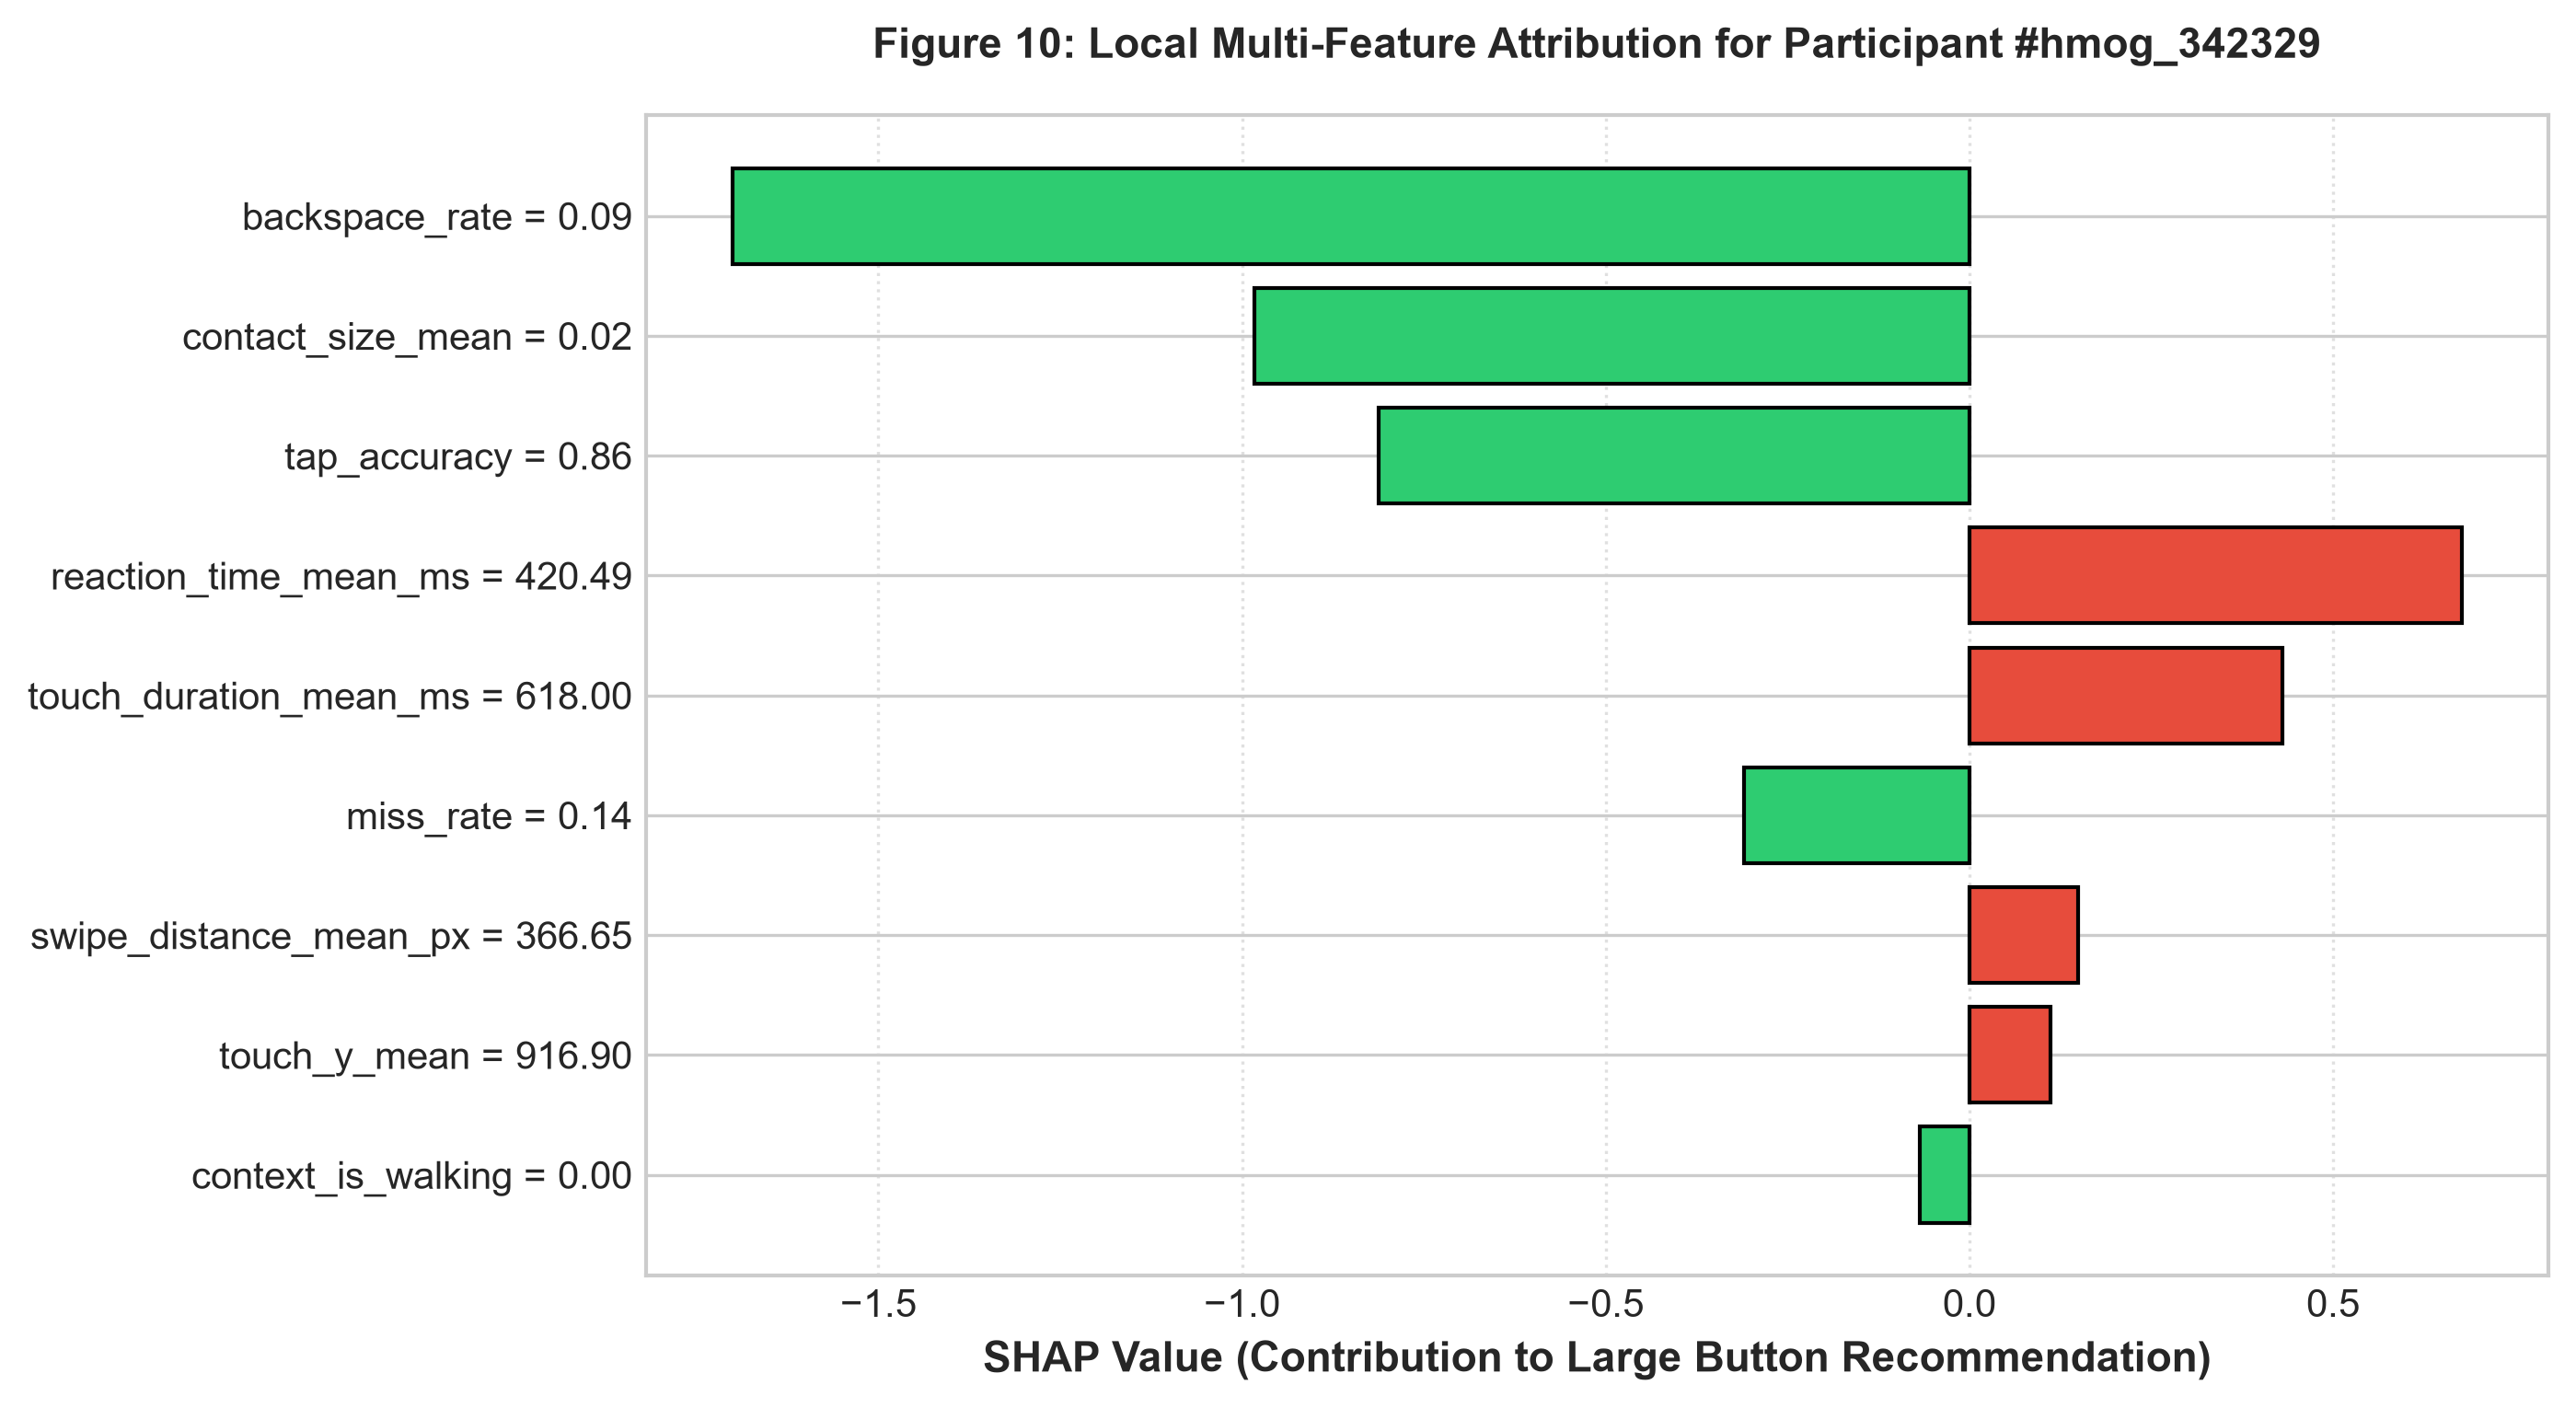

Done.


In [31]:
sample_idx = 10
sample_shap = shap_val_large[sample_idx]
sample_x = X_train.iloc[sample_idx]
top_n = 7
sorted_idx = np.argsort(np.abs(sample_shap))[-top_n:]

plt.figure(figsize=(9.5, 5))
colors = np.where(sample_shap[sorted_idx] > 0, '#e74c3c', '#2ecc71')
plt.barh(np.arange(top_n), sample_shap[sorted_idx], color=colors, edgecolor='black')
plt.yticks(np.arange(top_n), [f"{sample_x.index[i]} = {sample_x.iloc[i]:.2f}" for i in sorted_idx], fontsize=10)
plt.xlabel('SHAP Value (Contribution to Large Button Recommendation)', fontsize=11, fontweight='bold')
plt.title(f'Figure 10: Local Motor Attribution for Participant #{df_train.iloc[sample_idx]["user_id"]} (Cold-Start Adaptation Audit)', fontsize=11, pad=15, fontweight='bold')
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()
print('Done.')